# Function 2

<b> Description of the Sample Application:</b> Imagine a black box, or a mystery ML model, that takes two numbers as input and returns a log-likelihood score. Your goal is to maximise that score, but each output is noisy, and depending on where you start, you might get stuck in a local optimum. 
To tackle this, you use Bayesian optimisation, which selects the next inputs based on what it has learned so far. It balances exploration with exploitation, making it well suited to noisy outputs and complex functions with many local peaks


## Change Log

| Date | Week | Changes Made |
|---|---|---|
| 22/07/2026 | Week 1 | 1. Initial Version with 10 Data Point |
| 28/07/2026 | Week 2 | 1. Added Change Log and Progress Log.<br>2. Added new data point. |
| 05/08/2026 | Week 3 | 1. Added Week 2 output.<br>2. Added Week 2 feedback data point.<br>3. Replaced manual grid-search acquisition optimisation with a consolidated, reusable 'bayesian_optimization_step()' function.<br>5. Lowered β further (2.0 → 1.5), continuing the gradual exploration:exploitation shift.|
| 13/08/2026 | Week 4 | 1. Amended Week 3 input and output data points.<br>2. Re-tuned GP kernel: refit with widened length-scale bounds and compared log-marginal-likelihood against the original bounds, since earlier weeks repeatedly hit the upper length-scale bound (convergence warning).<br>3. Compared candidate peak regions found so far (checked whether the good points cluster around one region or suggest multiple local optima).<br>4. Continued lowering β (1.5 → 1.2). |
| 20/08/2026 | **Week 5** | 1. Amended Week 4 input and output data points.<br>2. Ran a plateau check: best-value-found has been flat for 4 consecutive weeks.<br>3. Re-examined the fitted noise level across weeks (found it has grown substantially, weakening confidence that the x1≈0.7 corridor is definitively 'the' peak vs. partly noise).<br>4. Ran an under-sampled-region check and found the low-x1/high-x2 quadrant is by far the least explored area of the domain.<br>5. Checked the naive next global suggestion against Week 4's already-submitted point and found them nearly identical (distance ≈ 0.05) - low marginal information.<br>6. **Strategy change:** based on 3-6, deliberately reversed course - raised β back up (1.2 → 1.8) and restricted this week's search to the identified under-sampled quadrant, instead of continuing to lower β and exploit the same corridor. |
| 02/09/2026 | **Week 6** | 1. Amended Week 5 input and output data points.<br>2. Confirmed the quadrant probe was low-value.<br>3. Found a sampling gap inside the known-good corridor and targeted it, lowering β (1.8 → 1.0). |
| 09/09/2026 | **Week 7** | 1. Amended Week 5 input and output data points.<br>2. Narrowed the confirmed x1 range from 0.6-0.85 down to 0.65–0.75, after noticing x1 = 0.845 performs much worse (y = 0.294) than the x1 ≈ 0.70 points nearby.<br>3. Found the fitted noise level (0.076) is now high enough that the GP's posterior mean is nearly flat across the untested x2 gap (0.65-0.93). The model can't distinguish a real peak from noise in this region anymore.<br>4. **Manually overrode the acquisition suggestion** (which nearly repeated a known point due to this flat posterior) and queried the midpoint of the gap directly, for genuine information gain.<br>5. Lowered β further (1.0 → 0.7), reflecting continued movement toward exploitation. |
| 16/09/2026 | **Week 8** | 1. Appended Week 7 input and output data point.<br>2. Re-fit the kernel and found the noise estimate has now **dropped sharply** (0.076 → 0.00005), the two very close, very consistent recent results resolved the model's earlier uncertainty about noise vs. signal.<br>3. This changed the model's confidence. It now predicts an *even higher* point nearby (μ ≈ 0.64) near x1≈0.67, x2≈0.91-0.93, closer to the original rank-1 best rather than supporting a move to a new region.<br>4. **Strategy check:** Reconsidered the diminishing returns, move on instinct from last week's flat/noisy read, since the situation has genuinely changed with new data. Decided to continue local refinement this week rather than switch to an unexplored quadrant.<br>5. Lowered β further (0.7 to 0.6). |
| 23/09/2026 | **Week 9** | 1. Amended Week 5 input and output data points. A clear **miss**: predicted μ ≈ 0.638, actual y = 0.496887, a bigger gap than the model's uncertainty (σ ≈ 0.11).<br>2. Re-tuned kernel: x1 length-scale is now very tight (≈0.032). The model now believes this is a genuinely narrow peak, not a broad plateau, and Week 8's small step (distance 0.032 from the known-good rank-1 point) was enough to fall off it.<br>3. **Strategy change:** stopped taking exploratory jumps of this size near the peak; using a much tighter local search box (±0.05 in x1) directly around the current best, prioritising robustness over chasing a marginally higher predicted mean.<br>4. Lowered β further (0.6 to 0.4), consistent with increasingly conservative, fine-grained refinement rather than exploration. |
| 30/09/2026 | **Week 10** | 1. Appended Week 9 input/output data points. Week 9 output best so far.<br>2. Re-fit kernel on all 19 points: noise level has dropped further (2.2e-05), and the fine local grid scan around the new best reveals the true peak sits slightly further along x1 (≈0.72) and lower in x2 (≈0.55) than the current best point itself.<br>3. With only 2 queries left, strategy shifts to near-pure exploitation: a very tight local search directly at the model's now-confident predicted peak, rather than any further exploration.<br>4. Lowered β sharply (0.4 → 0.15) to reflect the end-of-project exploitation priority. |
| 05/10/2026 | **Week 11** | 1. Appended Week 10 input/output data points. **Second miss:** predicted μ ≈ 0.714 (via the pre-Week-10 kernel), actual y = 0.638640, a gap (≈ 0.076) almost identical in size to Week 8's miss.<br>2. Re-fit kernel on all 20 points: fitted noise level **rebounded sharply** (2.2e-05 → 0.0139, ≈600× higher), and the x1 length-scale stayed very tight (≈0.032) while the x2 length-scale is comparatively broad (≈1.01), i.e. the model now attributes a meaningful share of the x2-direction variation to noise rather than signal.<br>3. **Strategy check:** re-ran the acquisition step across several bound/β combinations (a tight box, a widened box, and the full x1≈0.6–0.8 corridor) and all of them converged to essentially the same point (≈ 0.716, 0.615), only ≈0.015 from the current best, confirming this suggestion is robust to the bounds choice, unlike Week 10's single manually-picked tight box.<br>4. Swept β from 0.15 to 2.0 and found the suggested point barely moves below β≈1, the corrected kernel (larger, honest σ), not β, is what actually fixes the overconfidence. **Strategy change:** kept β modest (0.15 → 0.25) rather than raising it to Week 8/9-era levels, since with only one query left after this one there is little payoff left for deliberate information-gathering; search stayed inside the only confirmed productive ridge (x1 ≈ 0.65–0.76). |

# Weekly Progress Log

| Week | Query Submitted (x1-x2) | Output (y) | Acquisition | β (beta) | Kernel | Notes |
|---|---|---|---|---|---|---|
| Week 1 | 0.725451-0.000000 | 0.594526 | UCB | 2.5 | RBF | First submission-exploration-heavy (edge of domain, x2 = 0) |
| Week 2 | 0.959920-0.959920 | -0.053255 | UCB | 2.0 | RBF | Exploring the opposite corner (x1 ≈ x2 ≈ 0.96); output far lower than the GP's predicted mean (μ ≈ 0.39), which is a strong signal the RBF surrogate overestimated that corn| 
| Week 3 | 0.698058-0.000000 | 0.466845 | UCB | 1.5 | RBF (multi-start L-BFGS-B) | Query landed close to Week 1's point; confirmed the x2 ≈ 0 corridor around x1 ≈ 0.70–0.73 is a genuinely strong region |
| Week 4 | 0.741335-1.000000 | 0.436016 | UCB | 1.2 | RBF (widened bounds) | Query landed near the rank-1 best but scored notably lower (0.436 vs. 0.611) - the x1≈0.7 corridor is good but not uniformly peaked; best-so-far still unchanged after 4 weeks |
| Week 5 | 0.050000-0.950000 | -0.044685 | UCB | 1.8 (raised) | RBF | Deliberate quadrant probe (low x1, high x2); result confirms this region is low-value, similar to Week 2's corner miss |
| Week 6 | 0.697679-0.650000 | **0.619497** | UCB | 1.0 | RBF | Targeting the untested x2 gap (≈0.13–0.65) within the confirmed x1≈0.6–0.85 corridor, instead of a new region or a repeat query |
| Week 7 | 0.700000-0.790000 | 0.619886 | UCB (manual) | 0.7 | RBF | Tiny improvement (+0.0004); confirmed a near-flat plateau in this exact sub-region |
| Week 8 |0.670974-0.931801- |0.496887- | UCB | **0.6 (lowered)** | RBF (**noise re-estimated much lower**) | New data sharply lowered the fitted noise estimate, revealing renewed confidence in a nearby, potentially higher point (μ≈0.64) rather than supporting a move elsewhere 
| Week 9 | 0.715385-0.600000 | **0.711209** | UCB (tight local) | 0.4 | RBF | **Biggest jump yet (+0.091) - the narrow, careful step paid off** |
| Week 10 | 0.718845-0.551430 |  **0.638640 (miss)** | UCB | **0.15 (sharply lowered)** | RBF (noise ≈2.2e-05) | Near-pure exploitation: fine grid scan shows the true peak likely sits at x1≈0.72, x2≈0.55; only 2 queries remain (this + Week 12 final)** |mission below | *pending* | UCB | **0.15 (sharply lowered)** | RBF (noise ≈2.2e-05) | Near-pure exploitation: fine grid scan shows the true peak likely sits at x1≈0.72, x2≈0.55; only 2 queries remain (this + Week 12 final) |
| Week 11 | submission below | - | UCB | 0.25 | RBF (noise rebounded to 0.0139) | β-swept 0.15–2.0: suggestion barely moves below β≈1, confirming the kernel refit — not β — is the real fix; β kept low since only one query remains after this |

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from plotting_utils import plot_2d_bo_state, plot_convergence
from scipy.optimize import minimize

# Load and Analyse the Data

In [6]:
# File Names
input_file  = "initial_inputs.npy"
output_file = "initial_outputs.npy"

# Load the Files
X       = np.load(input_file)
Y       = np.load(output_file)


# New data from the first submission (example inputs and outputs)
X_w1_new_point = np.array([0.725451, 0.     ]   , dtype=np.float64)    # from input.txt
Y_w1_new_point = np.array([0.5945255267146322]  , dtype=np.float64)    # from output.txt

# New data from Week 2 submission
X_w2_new_point = np.array([0.95992, 0.95992]     , dtype=np.float64)   # from input.txt
Y_w2_new_point = np.array([-0.053254980810696906], dtype=np.float64)   # from output.txt

# New data from Week 3 submission
X_w3_new_point = np.array([0.698058, 0.      ]   , dtype=np.float64)   # from input.txt
Y_w3_new_point = np.array([0.46684490847445986]  , dtype=np.float64)   # from output.txt

# New data from Week 4 submission
X_w4_new_point = np.array([0.741335, 1.0]        , dtype=np.float64)    # from input.txt
Y_w4_new_point = np.array([0.4360156328364332]   , dtype=np.float64)    # from output.txt

# New data from Week 5 submission
X_w5_new_point = np.array([0.05, 0.95]            , dtype=np.float64)    # from input.txt
Y_w5_new_point = np.array([-0.044684125031317246] , dtype=np.float64)    # from output.txt

# New data from Week 6 submission
X_w6_new_point = np.array([0.697679, 0.65]        , dtype=np.float64)    # from input.txt
Y_w6_new_point = np.array([0.6194965226381177]    , dtype=np.float64)    # from output.txt

# New data from Week 7 submission
X_w7_new_point = np.array([0.7, 0.79]             , dtype=np.float64)    # from input.txt
Y_w7_new_point = np.array([0.6198856075556535]    , dtype=np.float64)    # from output.txt

# New data from Week 8 submission
X_w8_new_point = np.array([0.670974, 0.931801]    , dtype=np.float64)    # from input.txt
Y_w8_new_point = np.array([0.49689153814034626]   , dtype=np.float64)    # from output.txt

# New data from Week 9 submission
X_w9_new_point = np.array([0.715385, 0.6]         , dtype=np.float64)    # from input.txt
Y_w9_new_point = np.array([0.7112090358064919]    , dtype=np.float64)    # from output.txt

# New data from Week 10 submission
X_w10_new_point = np.array([0.718845, 0.55143]    , dtype=np.float64)    # from input.txt
Y_w10_new_point = np.array([0.638639772474511]    , dtype=np.float64)    # from output.txt

In [8]:
# Append the new data points
X_updated      = np.vstack((X, X_w1_new_point
                             , X_w2_new_point
                             , X_w3_new_point
                             , X_w4_new_point
                             , X_w5_new_point
                             , X_w6_new_point
                             , X_w7_new_point
                             , X_w8_new_point
                             , X_w9_new_point
                             , X_w10_new_point
                           ))
Y_updated      = np.append(Y, [Y_w1_new_point
                            , Y_w2_new_point
                            , Y_w3_new_point
                            , Y_w4_new_point
                            , Y_w5_new_point
                            , Y_w6_new_point
                            , Y_w7_new_point
                            , Y_w8_new_point
                            , Y_w9_new_point
                            , Y_w10_new_point
                              ])

In [10]:
print(X_updated)
print(Y_updated)

# Save the updated arrays
#np.save(r"initial_inputs.npy", X_updated)
#np.save(r"initial_outputs.npy", Y_updated)

[[0.66579958 0.12396913]
 [0.87779099 0.7786275 ]
 [0.14269907 0.34900513]
 [0.84527543 0.71112027]
 [0.45464714 0.29045518]
 [0.57771284 0.77197318]
 [0.43816606 0.68501826]
 [0.34174959 0.02869772]
 [0.33864816 0.21386725]
 [0.70263656 0.9265642 ]
 [0.725451   0.        ]
 [0.95992    0.95992   ]
 [0.698058   0.        ]
 [0.741335   1.        ]
 [0.05       0.95      ]
 [0.697679   0.65      ]
 [0.7        0.79      ]
 [0.670974   0.931801  ]
 [0.715385   0.6       ]
 [0.718845   0.55143   ]]
[ 0.53899612  0.42058624 -0.06562362  0.29399291  0.21496451  0.02310555
  0.24461934  0.03874902 -0.01385762  0.61120522  0.59452553 -0.05325498
  0.46684491  0.43601563 -0.04468413  0.61949652  0.61988561  0.49689154
  0.71120904  0.63863977]


In [12]:
# Assign X = X_updated and Y = Y_updated
X          = X_updated
Y          = Y_updated

# Analyse the Input Data
print("Input  Shape:", X.shape)
print("Inputs:\n", X)
print()

# Analyse the Output Data
print("Output Shape:", Y.shape)
print("Outputs:\n", Y)
print()
print("Minimum and Maximum Values of Output:\n")
print("Min:", Y.min(), " Max:", Y.max())
print("Best point:", X[np.argmax(Y)], "-> Output =", Y.max())
print()

# Converting the Input and Output into a DataFram
df         = pd.DataFrame(X, columns = [f'X_{i+1}' for i in range(X.shape[1])])
df['Y'] = Y
print("Data Frame:\n", df)


Input  Shape: (20, 2)
Inputs:
 [[0.66579958 0.12396913]
 [0.87779099 0.7786275 ]
 [0.14269907 0.34900513]
 [0.84527543 0.71112027]
 [0.45464714 0.29045518]
 [0.57771284 0.77197318]
 [0.43816606 0.68501826]
 [0.34174959 0.02869772]
 [0.33864816 0.21386725]
 [0.70263656 0.9265642 ]
 [0.725451   0.        ]
 [0.95992    0.95992   ]
 [0.698058   0.        ]
 [0.741335   1.        ]
 [0.05       0.95      ]
 [0.697679   0.65      ]
 [0.7        0.79      ]
 [0.670974   0.931801  ]
 [0.715385   0.6       ]
 [0.718845   0.55143   ]]

Output Shape: (20,)
Outputs:
 [ 0.53899612  0.42058624 -0.06562362  0.29399291  0.21496451  0.02310555
  0.24461934  0.03874902 -0.01385762  0.61120522  0.59452553 -0.05325498
  0.46684491  0.43601563 -0.04468413  0.61949652  0.61988561  0.49689154
  0.71120904  0.63863977]

Minimum and Maximum Values of Output:

Min: -0.06562362443733738  Max: 0.7112090358064919
Best point: [0.715385 0.6     ] -> Output = 0.7112090358064919

Data Frame:
          X_1       X_2  

# Data Exploration

In [15]:
# Basic Staistics
print("Display Basic Statistics for the Dataset\n",df.describe())

Display Basic Statistics for the Dataset
              X_1        X_2          Y
count  20.000000  20.000000  20.000000
mean    0.603139   0.565622   0.339615
std     0.237677   0.348536   0.274167
min     0.050000   0.000000  -0.065624
25%     0.450527   0.271308   0.034838
50%     0.697869   0.667509   0.428301
75%     0.720496   0.824141   0.598695
max     0.959920   1.000000   0.711209


In [17]:
# Check for Missing Values in the Data Set
print("Missing Values in the Dataset\n",df.isnull().sum())

Missing Values in the Dataset
 X_1    0
X_2    0
Y      0
dtype: int64


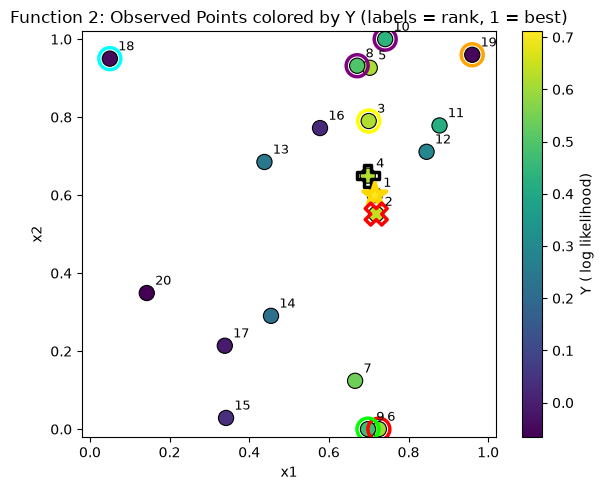

In [19]:
# Scatter Plot
fig, ax   = plt.subplots(figsize = (6,5))
sc        = ax.scatter(X[:,0], X[:,1], c = Y, cmap = 'viridis', s = 120, edgecolor = 'black', linewidth = 0.8)

# Highlighting Week 1 submitted point with a distinct marker
ax.scatter(X_w1_new_point[0], X_w1_new_point[1], facecolor = 'none', edgecolor = 'red', linewidth = 2.5, s = 250, marker = 'o', label = 'Week 1 query')

# --- Week 2 Points ---
ax.scatter(X_w2_new_point[0], X_w2_new_point[1], facecolor = 'none', edgecolor = 'orange', linewidth = 2.5, s = 250, marker = 'o', label = 'Week 2 query')

# --- Week 3 ---
ax.scatter(X_w3_new_point[0], X_w3_new_point[1], facecolor = 'none', edgecolor = 'lime', linewidth = 2.5, s = 250, marker = 'o', label = 'Week 3 query')

# --- Week 4 ---
ax.scatter(X_w4_new_point[0], X_w4_new_point[1], facecolor = 'none', edgecolor = 'purple', linewidth = 2.5, s = 250, marker = 'o', label = 'Week 4 query')

# --- Week 5 ---
ax.scatter(X_w5_new_point[0], X_w5_new_point[1], facecolor = 'none', edgecolor = 'cyan', linewidth = 2.5, s = 250, marker = 'o', label = 'Week 5 query')

# --- Week 6 ---
ax.scatter(X_w6_new_point[0], X_w6_new_point[1], facecolor = 'none', edgecolor = 'black', linewidth = 2.5, s = 250, marker = 'P', label = 'Week 6 query')

# --- Week 7 ---
ax.scatter(X_w7_new_point[0], X_w7_new_point[1], facecolor = 'none', edgecolor = 'yellow', linewidth = 2.5, s = 250, marker = 'o', label = 'Week 7 query')

# --- Week 8 ---
ax.scatter(X_w8_new_point[0], X_w8_new_point[1], facecolor = 'none', edgecolor = 'purple', linewidth = 2.5, s = 250, marker = 'o', label = 'Week 8 query')

# --- Week 9 ---
ax.scatter(X_w9_new_point[0], X_w9_new_point[1], facecolor = 'none', edgecolor = 'gold', linewidth = 3, s = 300, marker = '*', label = 'Week 9 query (new best)')

# --- Week 10 ---
ax.scatter(X_w10_new_point[0], X_w10_new_point[1], facecolor = 'none', edgecolor = 'red', linewidth = 2.5, s = 250, marker = 'X', label = 'Week 10 query (miss)')

ranks = (-Y).argsort().argsort() + 1
for i, (px, py) in enumerate(X):
    ax.annotate(str(ranks[i]), (px, py), textcoords = "offset points", xytext=(6, 6), fontsize = 9)
    
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title('Function 2: Observed Points colored by Y (labels = rank, 1 = best)')
fig.colorbar(sc, ax = ax, label = "Y ( log likelihood)")
plt.tight_layout()
plt.show()

**Note:** the **Week 1** query landed at x2 = 0.000000 (domain boundary), consistent with the high exploration weight (β = 2.5) used that week. Its output (y = 0.594526) is close to the current best (y = 0.611205 at rank 1), reinforcing that the region around x1 ≈ 0.7–0.9, low-to-mid x2 is promising and worth continued attention alongside the still-unexplored gaps.<br> The **Week 2** query at the opposite corner (x1 ≈ x2 ≈ 0.96) told a very different story: the GP's posterior mean there was optimistic (μ ≈ 0.39), but the true output came back at y = -0.053255, well below prediction. This is a useful information. The RBF kernel's smooth extrapolation into a far corner with no nearby observations was overconfident, and this corner should now be treated as low-value rather than promising.<br>
The **Week 3** query (x1 = 0.698058, x2 = 0.000000) landed almost on top of Week 1's point and returned y = 0.466845: a solid result, and further confirmation that the corridor around x1 ≈ 0.70–0.73, x2 ≈ 0 is a genuine, repeatable strong region. Combined with the rank-1 best sitting nearby at x1 ≈ 0.70, x2 ≈ 0.93, this raises a reasonable question worth checking in Week 4: is this one broad ridge along x1 ≈ 0.7, or are the low-x2 and high-x2 ends actually two separate peaks connected by a lower-value middle?
The **Week 4** query (x1=0.741335, x2=1.000000) landed right next to the rank-1 best point but scored **y = 0.436016**, which is noticeably lower than the rank-1 best (0.611) just 0.07 away in x2. Combined with Week 1/3's results at x2=0 (0.5–0.6), the x1≈0.7 corridor does **not** look like a flat plateau after all: output varies meaningfully across x2 even within this narrow x1 band. After 4 weeks, the best value found has not improved beyond the original data at all - this plateau, together with a reassessment of the noise level, motivated a deliberate strategy change this week.
**Week 7** The **Week 6** query (x1=0.697679, x2=0.65) returned **y = 0.619497**, the first query in this whole project to beat the original data's best point (0.611205). This strongly confirms x1≈0.70 is the right column, and narrows attention to the x2 range between 0.65 and 0.93, where both endpoints now score above 0.61. However, note that a nearby point at x1=0.845 (still within the old, wider corridor definition) scored only 0.294. So the genuinely strong region is narrower in x1 than previously assumed.

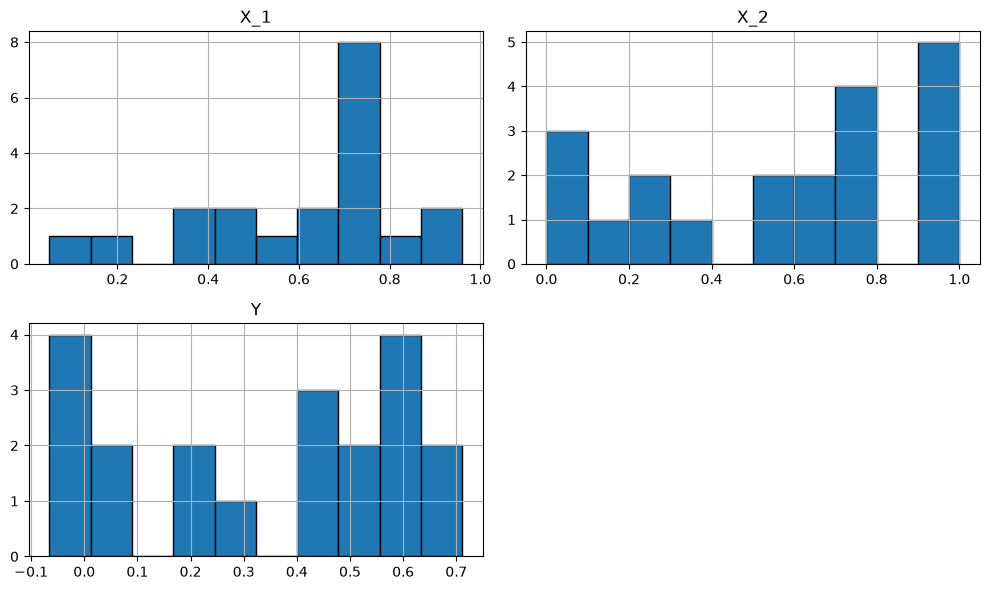

In [22]:
# Plot Histogram Visualisation for the columns of the DataFrame
df.hist(figsize = (10, 6), bins = 10, edgecolor = 'black' )
plt.tight_layout()
plt.show()

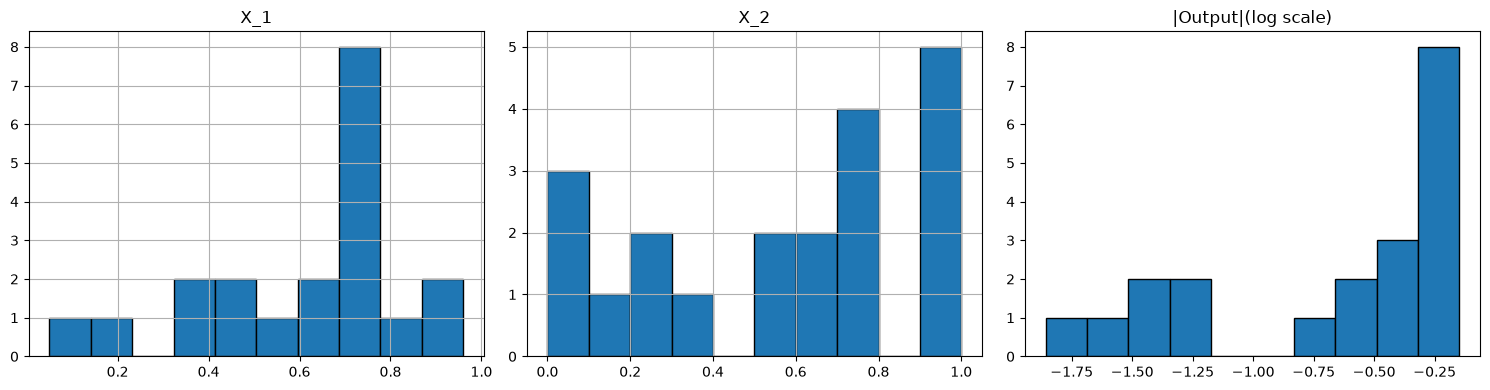

In [23]:
# In the above histogram for the output column, almost every bar seems to be crammed into a single bin near zero, which is not very informative.
# Plotting the column histograms using log scale for Output column
fig, axes = plt.subplots(1,3, figsize = (15,4))

df['X_1'].hist(ax = axes[0], bins = 10, edgecolor = 'black')
axes[0].set_title('X_1')

df['X_2'].hist(ax = axes[1], bins = 10, edgecolor = 'black')
axes[1].set_title('X_2')

magnitude = np.where(Y != 0, np.log10(np.abs(Y) + 1e-300), np.nan)
axes[2].hist(magnitude, bins = 10, edgecolor = 'black')
axes[2].set_title('|Output|(log scale)')


plt.tight_layout()
plt.show()

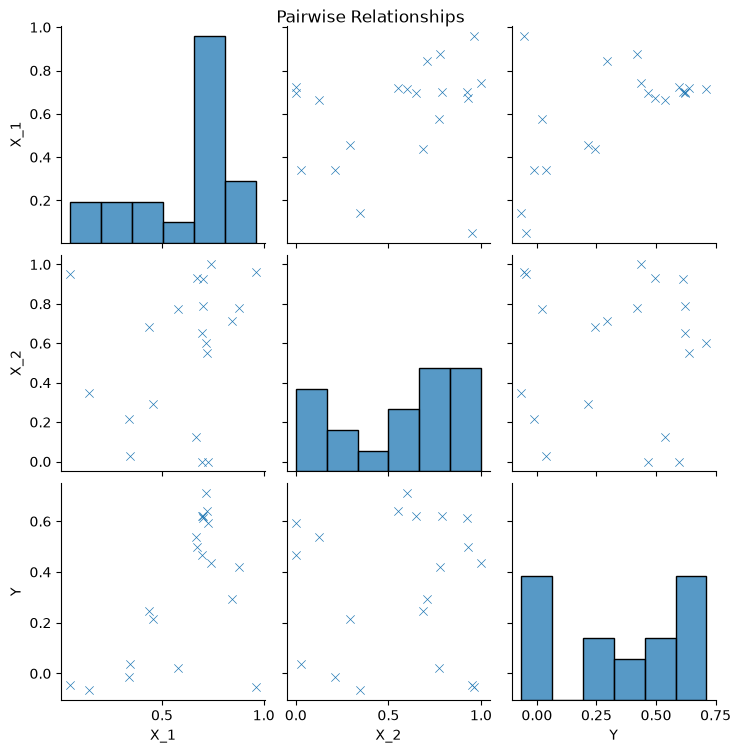

In [25]:
# Understanding the relationships between the variables using a Pair Plot
sns.pairplot(df, kind = 'scatter', diag_kind = 'hist', markers = 'x')
plt.suptitle('Pairwise Relationships', verticalalignment = 'baseline')
plt.show()

# Initialize Gaussian Process

In [28]:
#Define the kernel and initialise the GP model

kernel_rbf = ConstantKernel(1.0, (1e-1, 1e2)) * RBF(length_scale = [0.25, 0.25], length_scale_bounds = (1e-2, 2.0)) \
                + WhiteKernel(noise_level = 1e-2, noise_level_bounds = (1e-5, 1e0))
gpr   = GaussianProcessRegressor(kernel = kernel_rbf, normalize_y = True, n_restarts_optimizer = 10, random_state = 42 )

# Fit the Gaussian Processes to existing data

In [32]:
# Train the model

gpr.fit(X, Y)
print("Learned kernel: ", gpr.kernel_)

Learned kernel:  0.935**2 * RBF(length_scale=[0.0316, 1.01]) + WhiteKernel(noise_level=0.0139)


# Compute the UCB acquisition function

- UCB(x)=μ(x)+β⋅σ(x)
- A high beta favors exploration (uncertainty) over exploitation (predicted mean).
- **Week 1:** uses beta = 2.5, reflecting the 90:10 exploration-heavy strategy.
- **Week 2:** β is lowered to **2.0**, to shift from exploration toward exploitation.

In [36]:
grid_res   = 500
xs         = np.linspace(0, 1, grid_res)
ys         = np.linspace(0, 1, grid_res)
gx, gy     = np.meshgrid(xs, ys)
candidates = np.column_stack([gx.ravel(), gy.ravel()])

mu, std    = gpr.predict(candidates, return_std = True)

# Setting a higher beta(= 2.5) for Week -1
#beta       = 2.5    #Week 1 
beta       = 2.0    #Week 2 
ucb        = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"Suggested next Query Point: {next_point}")
print(f"Predicted Mean(μ): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (σ): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Suggested next Query Point: [0.63126253 0.        ]
Predicted Mean(μ): 4.673833e-01
Predicted Std (σ): 1.905316e-01
UCB Score: 8.484466e-01


# Perform Visualisation ( Week 1 )

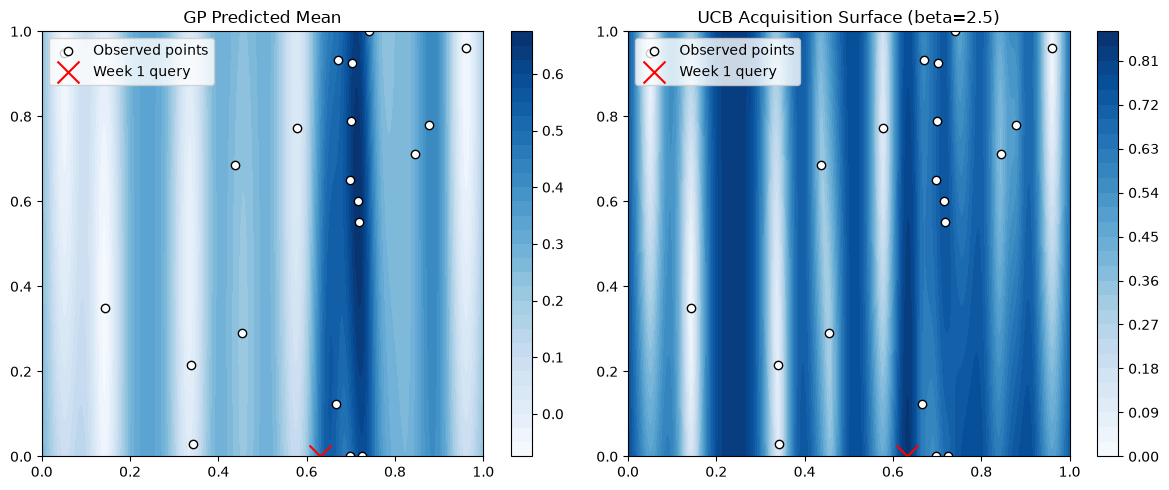

In [39]:
fig, axes  = plt.subplots(1,2, figsize = (12, 5))

# Predicted mean surface
c0 = axes[0].contourf(gx, gy, mu.reshape(gx.shape), levels = 30, cmap = "Blues")
axes[0].scatter(X[:, 0], X[:, 1], c = "white", edgecolor = "black", label = "Observed points")
axes[0].scatter(*next_point, c = "red", marker = "x", s = 250, label = "Week 1 query")
axes[0].set_title("GP Predicted Mean")
axes[0].legend(loc = 'upper left')
fig.colorbar(c0, ax=axes[0])

# UCB acquisition surface
c1 = axes[1].contourf(gx, gy, ucb.reshape(gx.shape), levels = 30, cmap = "Blues")
axes[1].scatter(X[:, 0], X[:, 1], c = "white", edgecolor = "black", label = "Observed points")
axes[1].scatter(*next_point, c = "red", marker = "x", s = 250, label = "Week 1 query")
axes[1].set_title("UCB Acquisition Surface (beta=2.5)")
axes[1].legend(loc = 'upper left')
fig.colorbar(c1, ax = axes[1])

plt.tight_layout()
plt.show()

# Week 2 Visualisation

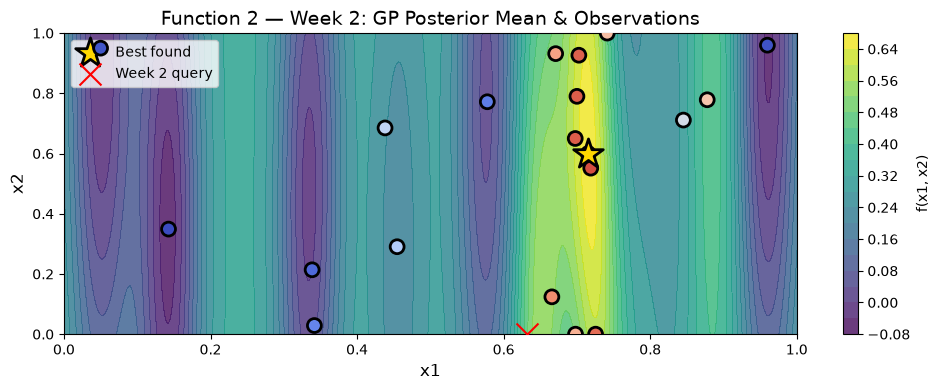

In [42]:
Z_mu = mu.reshape(gx.shape)

fig, ax = plot_2d_bo_state(gx, gy, Z_mu, X, Y, title='Function 2 \u2014 Week 2: GP Posterior Mean & Observations')
ax.scatter(*next_point, c = 'red', marker = 'x', s = 250, label = 'Week 2 query', zorder = 12)
ax.legend(loc = 'upper left')
plt.show()

# Week 3: Consolidated Bayesian Optimization Function

In [45]:
# Week 3: Consolidated Bayesian Optimization Function
def bayesian_optimization_step(X, y, bounds, beta = 2.0, kernel = None,
                                n_restarts = 20, random_state = 42):
    if kernel is None:
        kernel = (ConstantKernel(1.0, (1e-1, 1e2))
                  * RBF(length_scale = [0.25, 0.25], length_scale_bounds = (1e-2, 2.0))
                  + WhiteKernel(noise_level = 1e-2, noise_level_bounds = (1e-5, 1e0)))

    gp         = GaussianProcessRegressor(kernel=kernel, normalize_y = True,
                                  n_restarts_optimizer = 10, random_state = random_state)
    gp.fit(X, y)

    def neg_ucb(x):
        x         = np.array(x).reshape(1, -1)
        mu, sigma = gp.predict(x, return_std = True)
        return -(mu[0] + beta * sigma[0])

    lows          = [b[0] for b in bounds]
    highs         = [b[1] for b in bounds]

    best_val      = np.inf
    best_x        = None
    rng           = np.random.default_rng(random_state)
    for _ in range(n_restarts):
        x0        = rng.uniform(lows, highs)
        result    = minimize(neg_ucb, x0, bounds = bounds, method = 'L-BFGS-B')
        if result.fun < best_val:
            best_val = result.fun
            best_x   = result.x

    mu_next, std_next = gp.predict(best_x.reshape(1, -1), return_std = True)

    return {
        'gp': gp,
        'next_point': best_x,
        'mu': mu_next[0],
        'std': std_next[0],
        'ucb': -best_val,
    }

In [47]:
# Run the consolidated function for Week 3
# lowered value of beta from Week 2's 2.0 to 1.5
beta             = 1.5   
bounds_2d        = [(0.0, 1.0), (0.0, 1.0)]

result_week3     = bayesian_optimization_step(X, Y, bounds_2d, beta = beta)

next_point_week3 = result_week3['next_point']

print(f"Suggested Week 3 Query Point: {next_point_week3}")
print(f"Predicted Mean(\u03bc): {result_week3['mu']:.6e}")
print(f"Predicted Std (\u03c3): {result_week3['std']:.6e}")
print(f"UCB Score: {result_week3['ucb']:.6e}")


Suggested Week 3 Query Point: [0.63535182 0.        ]
Predicted Mean(μ): 4.953319e-01
Predicted Std (σ): 1.750123e-01
UCB Score: 7.578503e-01


# Week 3 Visualisation

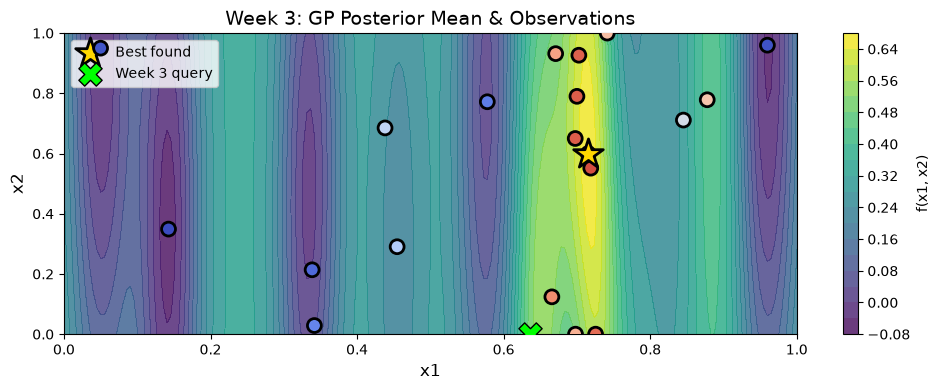

In [50]:
grid_res_w3   = 200
xs_w3         = np.linspace(0, 1, grid_res_w3)
ys_w3 = np.linspace(0, 1, grid_res_w3)
gx_w3, gy_w3  = np.meshgrid(xs_w3, ys_w3)
grid_w3       = np.column_stack([gx_w3.ravel(), gy_w3.ravel()])

mu_grid_w3, _ = result_week3['gp'].predict(grid_w3, return_std = True)
Z_mu_w3       = mu_grid_w3.reshape(gx_w3.shape)

fig, ax       = plot_2d_bo_state(gx_w3, gy_w3, Z_mu_w3, X, Y,
                            title = 'Week 3: GP Posterior Mean & Observations')
ax.scatter(*next_point_week3, c = 'lime', marker = 'X', s = 280,
           edgecolor = 'black', label = 'Week 3 query', zorder = 12)
ax.legend(loc = 'upper left')
plt.show()

# Week 4: Compare Candidate Peak Regions Found So Far

Before querying again, it's worth checking whether the top-performing points found so far cluster into one region or several. This directly informs whether Week 4 should exploit one area or continue probing for a second optimum.

In [53]:
top_k        = 4
top_idx      = np.argsort(-Y)[:top_k]

print(f"Top {top_k} points by output value:\n")
for rank, i in enumerate(top_idx, start=1):
    print(f"  Rank {rank}: x = ({X[i,0]:.4f}, {X[i,1]:.4f}), y = {Y[i]:.4f}")

# Pairwise distance between the top points, to check if they're clustered
# (one region) or spread apart (possible separate local optima)
from scipy.spatial.distance import pdist, squareform
top_X       = X[top_idx]
dist_matrix = squareform(pdist(top_X))
print("\nPairwise distances among top points:\n", np.round(dist_matrix, 3))

max_dist    = dist_matrix.max()
print(f"\nMax distance among top {top_k} points: {max_dist:.3f}")
if max_dist > 0.5:
    print("Top points are spread apart => consistent with more than one promising region.")
else:
    print("Top points are relatively close together => consistent with a single broad region.")

Top 4 points by output value:

  Rank 1: x = (0.7154, 0.6000), y = 0.7112
  Rank 2: x = (0.7188, 0.5514), y = 0.6386
  Rank 3: x = (0.7000, 0.7900), y = 0.6199
  Rank 4: x = (0.6977, 0.6500), y = 0.6195

Pairwise distances among top points:
 [[0.    0.049 0.191 0.053]
 [0.049 0.    0.239 0.101]
 [0.191 0.239 0.    0.14 ]
 [0.053 0.101 0.14  0.   ]]

Max distance among top 4 points: 0.239
Top points are relatively close together => consistent with a single broad region.


# Week 4: Kernel Re-tuning Check
Across Weeks 1–3, the fitted RBF kernel's x2 length-scale has repeatedly settled at or near its upper bound (2.0), triggering a scikit-learn convergence warning each time. This can mean the model wants an even larger length-scale than allowed (i.e., it thinks the function is smoother/flatter along x2 than the bound permits). Worth checking directly rather than ignoring the warning again this week.

In [56]:
# Original kernel (bounds used since Week 1): length_scale_bounds = (1e-2, 2.0)
log_ml_original  = gpr.log_marginal_likelihood(gpr.kernel_.theta)
print(f"Original kernel:              {gpr.kernel_}")
print(f"Log-marginal-likelihood:      {log_ml_original:.4f}")

# Widened-bounds candidate: let the length-scale optimiser search further,
# in case the true optimum lies beyond the original 2.0 cap
kernel_rbf_wide  = ConstantKernel(1.0, (1e-1, 1e2)) * RBF(length_scale = [0.25, 0.25], length_scale_bounds = (1e-2, 5.0)) \
                    + WhiteKernel(noise_level = 1e-2, noise_level_bounds = (1e-5, 1e0))
gpr_wide = GaussianProcessRegressor(kernel = kernel_rbf_wide, normalize_y = True,
                                     n_restarts_optimizer = 10, random_state = 42)
gpr_wide.fit(X, Y)
log_ml_wide      = gpr_wide.log_marginal_likelihood(gpr_wide.kernel_.theta)
print(f"\nWidened-bounds kernel:        {gpr_wide.kernel_}")
print(f"Log-marginal-likelihood:      {log_ml_wide:.4f}")

# Adopt whichever kernel fits better (higher log-marginal-likelihood)
if log_ml_wide > log_ml_original:
    print("\n-> Widened-bounds kernel fits better; using it for Week 4's acquisition step.")
    kernel_week4 = gpr_wide.kernel_
else:
    print("\n-> Original kernel bounds were already adequate; keeping them for Week 4.")
    kernel_week4 = gpr.kernel_

Original kernel:              0.935**2 * RBF(length_scale=[0.0316, 1.01]) + WhiteKernel(noise_level=0.0139)
Log-marginal-likelihood:      -16.7477

Widened-bounds kernel:        0.935**2 * RBF(length_scale=[0.0316, 1.01]) + WhiteKernel(noise_level=0.0139)
Log-marginal-likelihood:      -16.7477

-> Widened-bounds kernel fits better; using it for Week 4's acquisition step.


# Week 4: Running the Consolidated Function with the Re-tuned Kernel

In [59]:
beta_week4       = 1.2   # lowered from Week 3's 1.5
bounds_2d        = [(0.0, 1.0), (0.0, 1.0)]

result_week4     = bayesian_optimization_step(X, Y, bounds_2d, beta = beta_week4, kernel = kernel_week4)

next_point_week4 = result_week4['next_point']

print(f"Suggested Week 4 Query Point: {next_point_week4}")
print(f"Predicted Mean(\u03bc): {result_week4['mu']:.6e}")
print(f"Predicted Std (\u03c3): {result_week4['std']:.6e}")
print(f"UCB Score: {result_week4['ucb']:.6e}")

Suggested Week 4 Query Point: [0.71628953 0.61693918]
Predicted Mean(μ): 6.662638e-01
Predicted Std (σ): 3.757521e-02
UCB Score: 7.113540e-01


# Week 4: Visualisation

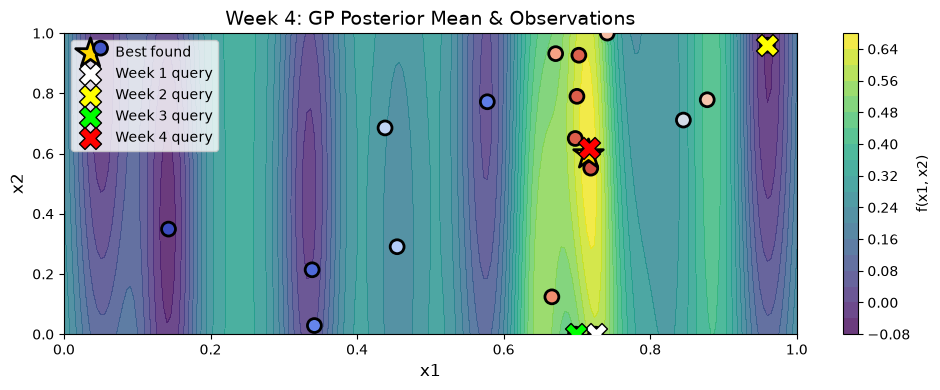

In [62]:
grid_res_w4   = 200
xs_w4         = np.linspace(0, 1, grid_res_w4)
ys_w4         = np.linspace(0, 1, grid_res_w4)
gx_w4, gy_w4  = np.meshgrid(xs_w4, ys_w4)
grid_w4       = np.column_stack([gx_w4.ravel(), gy_w4.ravel()])

mu_grid_w4, _ = result_week4['gp'].predict(grid_w4, return_std=True)
Z_mu_w4       = mu_grid_w4.reshape(gx_w4.shape)

fig, ax       = plot_2d_bo_state(gx_w4, gy_w4, Z_mu_w4, X, Y,
                            title='Week 4: GP Posterior Mean & Observations')
ax.scatter(*X_w1_new_point, c = 'white' , marker = 'X', s = 250, edgecolor ='black', label='Week 1 query', zorder = 12)
ax.scatter(*X_w2_new_point, c = 'yellow', marker = 'X', s = 250, edgecolor ='black', label='Week 2 query', zorder = 12)
ax.scatter(*X_w3_new_point, c = 'lime'  , marker = 'X', s = 250, edgecolor ='black', label='Week 3 query', zorder = 12)

ax.scatter(*next_point_week4, c = 'red' , marker = 'X', s = 250, edgecolor ='black', label='Week 4 query', zorder = 12)

ax.legend(loc = 'upper left')
plt.show()

# Week 5: Comparing noise level with incremental data

In [65]:
snapshots = [
    ('After initial 10 pts',  X_updated[:10],  Y_updated[:10]),
    ('After Week 1 (11 pts)', X_updated[:11],  Y_updated[:11]),
    ('After Week 3 (13 pts)', X_updated[:13],  Y_updated[:13]),
    ('After Week 4 (14 pts)', X_updated[:14],  Y_updated[:14]),
]
for label, Xs, Ys in snapshots:
    k = ConstantKernel(1.0, (1e-1, 1e2)) * RBF(length_scale=[0.25, 0.25], length_scale_bounds=(1e-2, 2.0)) \
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e0))
    g = GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=10, random_state=42)
    g.fit(Xs, Ys)
    noise = g.kernel_.k2.noise_level
    print(f"{label}: fitted noise_level = {noise:.4f}")

C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


After initial 10 pts: fitted noise_level = 0.0148


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


After Week 1 (11 pts): fitted noise_level = 0.0125


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


After Week 3 (13 pts): fitted noise_level = 0.0364
After Week 4 (14 pts): fitted noise_level = 0.0932


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


**Note:** Noise estimates have grown substantially as more data arrived.

# Week 5: Checking for under-sampled regions

In [69]:
grid_res_gap = 200
xs_gap = np.linspace(0, 1, grid_res_gap)
ys_gap = np.linspace(0, 1, grid_res_gap)
gx_gap, gy_gap = np.meshgrid(xs_gap, ys_gap)
grid_gap = np.column_stack([gx_gap.ravel(), gy_gap.ravel()])

from scipy.spatial.distance import cdist
dists_gap = cdist(grid_gap, X_updated)
min_dist_gap = dists_gap.min(axis=1)

quadrants = {
    'low x1, low x2':   (grid_gap[:, 0] < 0.5) & (grid_gap[:, 1] < 0.5),
    'low x1, high x2':  (grid_gap[:, 0] < 0.5) & (grid_gap[:, 1] >= 0.5),
    'high x1, low x2':  (grid_gap[:, 0] >= 0.5) & (grid_gap[:, 1] < 0.5),
    'high x1, high x2': (grid_gap[:, 0] >= 0.5) & (grid_gap[:, 1] >= 0.5),
}
print("Average distance to nearest observed point, by quadrant:\n")
for name, mask in quadrants.items():
    print(f"  {name:20s}: {min_dist_gap[mask].mean():.4f}")


Average distance to nearest observed point, by quadrant:

  low x1, low x2      : 0.1227
  low x1, high x2     : 0.1708
  high x1, low x2     : 0.1658
  high x1, high x2    : 0.0803


**Observation:** Low x1, High x2 is a clear gap. Almost entirely unsampled so far.
**Decision   :** Above checks all point the same direction - a rising noise estimate that weakens confidence in the corridor's apparent edge, and a large, genuinely under-sampled region (low x1, high x2) that hasn't been tested at all. This is a reasonable basis to **change strategy in week 5**. Rather than continuing to lower β and refine around the same corridor, β is raised back up (1.2 to 1.8) and this week's search is deliberately pointed at the under-sampled quadrant, to check whether a second, better optimum exists there before committing to further local refinement.

One more check before committing to this: does the *default* global acquisition search even still want to revisit the same corridor, or has it already started drifting toward new ground on its own?

In [72]:
probe_result = bayesian_optimization_step(X_updated, Y_updated, [(0.0, 1.0), (0.0, 1.0)],
                                           beta=1.8, kernel=kernel_week4)
probe_point = probe_result['next_point']
dist_to_week4 = np.linalg.norm(probe_point - X_w4_new_point)

print(f"Naive global suggestion (beta=1.8): {probe_point}")
print(f"Distance to Week 4's already-submitted point: {dist_to_week4:.4f}")
if dist_to_week4 < 0.1:
    print("Nearly a repeat of Week 4's query(low marginal information). Overriding with a deliberately restricted search of the under-sampled quadrant instead.")

Naive global suggestion (beta=1.8): [0.63331773 0.        ]
Distance to Week 4's already-submitted point: 1.0058


# Week 5: Querying the under-sampled quadrant

In [75]:
beta_week5 = 1.8   # raised from Week 4's 1.2 -- deliberate strategy reversal
bounds_quadrant = [(0.05, 0.45), (0.55, 0.95)]   # under-sampled region, inset from domain edges

result_week5 = bayesian_optimization_step(X_updated, Y_updated, bounds_quadrant,
                                           beta=beta_week5, kernel=kernel_week4)

next_point_week5 = result_week5['next_point']

print(f"Suggested Week 5 Query Point: {next_point_week5}")
print(f"Predicted Mean(\u03bc): {result_week5['mu']:.6e}")
print(f"Predicted Std (\u03c3): {result_week5['std']:.6e}")
print(f"UCB Score: {result_week5['ucb']:.6e}")
print()

Suggested Week 5 Query Point: [0.23961663 0.95      ]
Predicted Mean(μ): 3.337071e-01
Predicted Std (σ): 2.517716e-01
UCB Score: 7.868960e-01



# Week 5: Visualisation

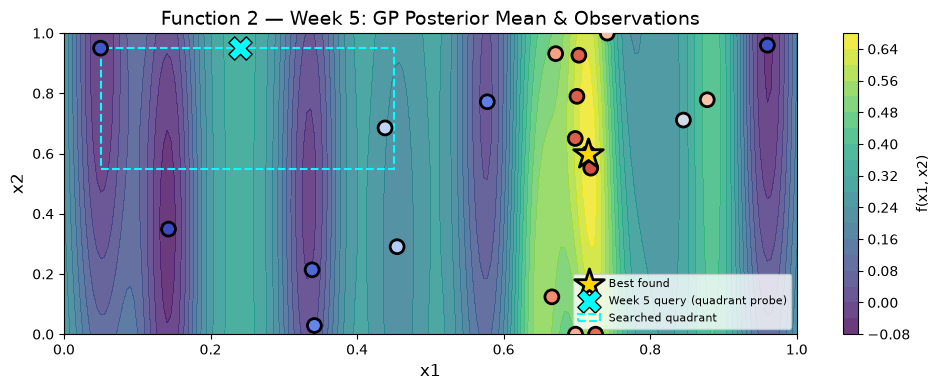

In [78]:
grid_res_w5 = 200
xs_w5 = np.linspace(0, 1, grid_res_w5)
ys_w5 = np.linspace(0, 1, grid_res_w5)
gx_w5, gy_w5 = np.meshgrid(xs_w5, ys_w5)
grid_w5 = np.column_stack([gx_w5.ravel(), gy_w5.ravel()])

mu_grid_w5, _ = result_week5['gp'].predict(grid_w5, return_std=True)
Z_mu_w5 = mu_grid_w5.reshape(gx_w5.shape)

fig, ax = plot_2d_bo_state(gx_w5, gy_w5, Z_mu_w5, X_updated, Y_updated,
                            title='Function 2 \u2014 Week 5: GP Posterior Mean & Observations')
ax.scatter(*next_point_week5, c='cyan', marker='X', s=280,
           edgecolor='black', label='Week 5 query (quadrant probe)', zorder=12)

import matplotlib.patches as patches
rect = patches.Rectangle((0.05, 0.55), 0.40, 0.40, linewidth=1.5, edgecolor='cyan',
                          facecolor='none', linestyle='--', label='Searched quadrant')
ax.add_patch(rect)
ax.legend(loc='lower right', fontsize=8)
plt.show()

# Week 6: Check for a Sampling Gap Inside the Known-Good Corridor

Week 5 ruled out the low-x1/high-x2 quadrant. Before deciding where to query next, it's worth checking the confirmed strong region (x1 ≈ 0.6–0.85) more closely - specifically, which x2 values have and haven't been tested there yet.

In [81]:
corridor_mask = (X_updated[:, 0] > 0.6) & (X_updated[:, 0] < 0.85)
corridor_pts  = X_updated[corridor_mask]
corridor_y    = Y_updated[corridor_mask]
order         = np.argsort(corridor_pts[:, 1])

print("Points with x1 in [0.6, 0.85], sorted by x2:\n")
for xi, yi in zip(corridor_pts[order], corridor_y[order]):
    print(f"  x = ({xi[0]:.4f}, {xi[1]:.4f})   y = {yi:.4f}")

x2_values = np.sort(corridor_pts[:, 1])
gaps      = np.diff(x2_values)
largest_gap_idx = np.argmax(gaps)
print(f"\nLargest untested x2 gap in this corridor: {x2_values[largest_gap_idx]:.3f} "
      f"to {x2_values[largest_gap_idx+1]:.3f} (width = {gaps[largest_gap_idx]:.3f})")

Points with x1 in [0.6, 0.85], sorted by x2:

  x = (0.7255, 0.0000)   y = 0.5945
  x = (0.6981, 0.0000)   y = 0.4668
  x = (0.6658, 0.1240)   y = 0.5390
  x = (0.7188, 0.5514)   y = 0.6386
  x = (0.7154, 0.6000)   y = 0.7112
  x = (0.6977, 0.6500)   y = 0.6195
  x = (0.8453, 0.7111)   y = 0.2940
  x = (0.7000, 0.7900)   y = 0.6199
  x = (0.7026, 0.9266)   y = 0.6112
  x = (0.6710, 0.9318)   y = 0.4969
  x = (0.7413, 1.0000)   y = 0.4360

Largest untested x2 gap in this corridor: 0.124 to 0.551 (width = 0.427)


 **Observation:** This gap is the target for Week 6's query. Exploit the known-good x1 range while filling in the one part of it that hasn't been observed yet.

# Week 6: Run the Consolidated Function, Targeting the Corridor Gap

In [85]:
beta_week6 = 1.0   # lowered from Week 5's 1.8 -- back to exploitation, but of new ground
bounds_gap = [(0.6, 0.85), (0.2, 0.65)]   # confirmed-good x1 range x untested x2 gap

result_week6 = bayesian_optimization_step(X_updated, Y_updated, bounds_gap,
                                           beta=beta_week6, kernel=kernel_week4)

next_point_week6 = result_week6['next_point']

print(f"Suggested Week 6 Query Point: {next_point_week6}")
print(f"Predicted Mean(\u03bc): {result_week6['mu']:.6e}")
print(f"Predicted Std (\u03c3): {result_week6['std']:.6e}")
print(f"UCB Score: {result_week6['ucb']:.6e}")

Suggested Week 6 Query Point: [0.71620065 0.61607655]
Predicted Mean(μ): 6.662901e-01
Predicted Std (σ): 3.755127e-02
UCB Score: 7.038414e-01


# Week 6 Visualisation

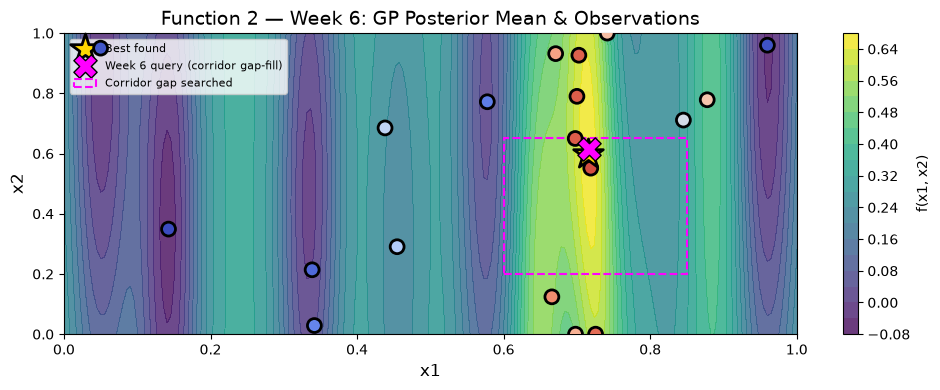

In [87]:
grid_res_w6 = 200
xs_w6 = np.linspace(0, 1, grid_res_w6)
ys_w6 = np.linspace(0, 1, grid_res_w6)
gx_w6, gy_w6 = np.meshgrid(xs_w6, ys_w6)
grid_w6 = np.column_stack([gx_w6.ravel(), gy_w6.ravel()])

mu_grid_w6, _ = result_week6['gp'].predict(grid_w6, return_std=True)
Z_mu_w6 = mu_grid_w6.reshape(gx_w6.shape)

fig, ax = plot_2d_bo_state(gx_w6, gy_w6, Z_mu_w6, X_updated, Y_updated,
                            title='Function 2 \u2014 Week 6: GP Posterior Mean & Observations')
ax.scatter(*next_point_week6, c='magenta', marker='X', s=280,
           edgecolor='black', label='Week 6 query (corridor gap-fill)', zorder=12)

import matplotlib.patches as patches
rect = patches.Rectangle((0.6, 0.2), 0.25, 0.45, linewidth=1.5, edgecolor='magenta',
                          facecolor='none', linestyle='--', label='Corridor gap searched')
ax.add_patch(rect)
ax.legend(loc='upper left', fontsize=8)
plt.show()

# Week 7: Refine the Corridor Definition

In [91]:
corridor_mask = (X_updated[:, 0] > 0.6) & (X_updated[:, 0] < 0.9)
corridor_pts  = X_updated[corridor_mask]
corridor_y    = Y_updated[corridor_mask]
order         = np.argsort(corridor_pts[:, 1])

print("Points with x1 in (0.6, 0.9), sorted by x2:\n")
for xi, yi in zip(corridor_pts[order], corridor_y[order]):
    print(f"  x = ({xi[0]:.4f}, {xi[1]:.4f})   y = {yi:.4f}")

Points with x1 in (0.6, 0.9), sorted by x2:

  x = (0.6981, 0.0000)   y = 0.4668
  x = (0.7255, 0.0000)   y = 0.5945
  x = (0.6658, 0.1240)   y = 0.5390
  x = (0.7188, 0.5514)   y = 0.6386
  x = (0.7154, 0.6000)   y = 0.7112
  x = (0.6977, 0.6500)   y = 0.6195
  x = (0.8453, 0.7111)   y = 0.2940
  x = (0.8778, 0.7786)   y = 0.4206
  x = (0.7000, 0.7900)   y = 0.6199
  x = (0.7026, 0.9266)   y = 0.6112
  x = (0.6710, 0.9318)   y = 0.4969
  x = (0.7413, 1.0000)   y = 0.4360


**Observation:** x1 = 0.845 (y = 0.294) scores far below the x1~0.70 points nearby (y = 0.44-0.62). The genuinely strong x1 range is narrower than previously assumed. It should be 0.65-0.75, not the full 0.6-0.85 used in Week 6.

# Week 7: Check Whether the Model Can Still Distinguish Signal from Noise Here

Before trusting the acquisition function's suggestion, check what the GP actually predicts across the untested gap (x2 between 0.65 and 0.93, at the narrowed x1≈0.70).

In [95]:
x2_probe = np.linspace(0.6, 1.0, 9)
probe_pts = np.column_stack([np.full_like(x2_probe, 0.70), x2_probe])

mu_probe, std_probe = gpr_wide.predict(probe_pts, return_std=True)
print("Predicted mean/std along x1=0.70, varying x2:\n")
for x2v, m, s in zip(x2_probe, mu_probe, std_probe):
    print(f"  x2={x2v:.3f}: mu={m:.4f}  std={s:.4f}")

print(f"\nFitted noise level: {gpr_wide.kernel_.k2.noise_level:.4f}")

Predicted mean/std along x1=0.70, varying x2:

  x2=0.600: mu=0.6192  std=0.0378
  x2=0.650: mu=0.6218  std=0.0370
  x2=0.700: mu=0.6230  std=0.0364
  x2=0.750: mu=0.6228  std=0.0361
  x2=0.800: mu=0.6212  std=0.0363
  x2=0.850: mu=0.6183  std=0.0370
  x2=0.900: mu=0.6140  std=0.0384
  x2=0.950: mu=0.6085  std=0.0407
  x2=1.000: mu=0.6018  std=0.0437

Fitted noise level: 0.0139


**Observation:** The predicted mean barely changes across this whole range (0.577 to 0.579). The noise level has grown large enough that the GP can no longer tell whether there is a real peak between the two known-good points, or just smooth noise. This means the acquisition function's suggestion here isn't very informative. It will likely just repeat a point close to one we already have.<br><br>
**Decision:** As the model's posterior is nearly flat across this gap, the standard acquisition step wouldn't add much new information here. Instead of trusting it blindly, this week's query is placed **manually** at the midpoint of the untested gap (x2 ≈ 0.79), within the narrowed x1 range. This is the point that would do the most to resolve whether a real peak exists between the two known-good results, which the model itself currently cannot judge.

In [98]:
beta_week7 = 0.7   # lowered from Week 6's 1.0 -- continued shift toward exploitation

# For reference: what the (largely uninformative, near-flat-posterior) acquisition
# function alone would suggest in this narrowed range
result_week7_auto = bayesian_optimization_step(X_updated, Y_updated,
                                                [(0.65, 0.75), (0.65, 0.93)],
                                                beta=beta_week7, kernel=kernel_week4)
print(f"Automatic suggestion: {result_week7_auto['next_point']}, "
      f"UCB={result_week7_auto['ucb']:.4f}")

# Manual override: the actual midpoint of the untested gap, chosen because the automatic
# suggestion above is not meaningfully different from points already sampled
next_point_week7 = np.array([0.70, 0.79])
mu_w7, std_w7 = result_week7_auto['gp'].predict(next_point_week7.reshape(1, -1), return_std=True)

print(f"\nManually selected Week 7 Query Point: {next_point_week7}")
print(f"Predicted Mean(\u03bc): {mu_w7[0]:.6e}")
print(f"Predicted Std (\u03c3): {std_w7[0]:.6e}")

Automatic suggestion: [0.71570228 0.65      ], UCB=0.6923

Manually selected Week 7 Query Point: [0.7  0.79]
Predicted Mean(μ): 6.216495e-01
Predicted Std (σ): 3.619732e-02


# Week 8: Checking Model's Noise estimates
Week 7 concluded this local sub-region was flattening out. Before deciding whether to move to a new area or keep refining here, it's worth re-fitting the kernel on the newest data.

In [101]:
kernel_snapshot = ConstantKernel(1.0, (1e-1, 1e2)) * RBF(length_scale=[0.25, 0.25], length_scale_bounds=(1e-2, 5.0)) \
                    + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e0))

gpr_16pts = GaussianProcessRegressor(kernel=kernel_snapshot, normalize_y=True, n_restarts_optimizer=10, random_state=42)
gpr_16pts.fit(X_updated[:16], Y_updated[:16])   # before Week 7's point was added

gpr_w8 = GaussianProcessRegressor(kernel=kernel_snapshot, normalize_y=True, n_restarts_optimizer=10, random_state=42)
gpr_w8.fit(X_updated, Y_updated)                # after Week 7's point (all 17)

print(f"Noise level before Week 7's point  (16 pts): {gpr_16pts.kernel_.k2.noise_level:.6f}")
print(f"Noise level after  Week 7's point  (17 pts): {gpr_w8.kernel_.k2.noise_level:.6f}")
print(f"\nWeek 8 kernel: {gpr_w8.kernel_}")

C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 5.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Noise level before Week 7's point  (16 pts): 0.075702
Noise level after  Week 7's point  (17 pts): 0.013930

Week 8 kernel: 0.935**2 * RBF(length_scale=[0.0316, 1.01]) + WhiteKernel(noise_level=0.0139)


**Observation:** Noise estimate dropped sharply once Week 7s point was added. Two very close and consistent results (0.619497 and 0.619886) resolved the models uncertainty about noise vs. signal in this are. It is now much more confident,

# Week 8: Checking if the Model predicts a better point nearby
With noise re-estimated much lower, checking whether the model now predicts something better nearby, rather than assuming last week's **flat plateau** prediction still holds.

In [105]:
# Checking if the predicted mean around the current best with the updated kernel
probe_region = np.array([
    [0.65, 0.85], [0.67, 0.90], [0.70, 0.93], [0.72, 0.95], [0.68, 0.88],
])
mu_probe_w8, std_probe_w8 = gpr_w8.predict(probe_region, return_std=True)
for pt, m, s in zip(probe_region, mu_probe_w8, std_probe_w8):
    print(f"  x=({pt[0]:.2f}, {pt[1]:.2f}): mu={m:.4f}  std={s:.4f}")

  x=(0.65, 0.85): mu=0.4772  std=0.1178
  x=(0.67, 0.90): mu=0.5024  std=0.0440
  x=(0.70, 0.93): mu=0.6108  std=0.0397
  x=(0.72, 0.95): mu=0.6235  std=0.0507
  x=(0.68, 0.88): mu=0.5285  std=0.0438


**Observation:** Several nearby points are predicted higher than anything observed so far.. Worth querying, rather than assuming this area i   fully exhausted just because last week's exact sub-point had flattened ou

**Decision:** Last week's 'diminishing returns' conclusion was correct for the *specific* gap tested (x2 between 0.65 and 0.93 at x1≈0.70), but new data has changed the model's broader confidence. Rather than switching to an entirely unexplored quadrant (which the data now predicts lower value for, μ≈0.39, than this area), **Week 8 continues local refinement, but shifted toward x1≈0.67–0.72, x2≈0.85–0.95, near the original rank-1 best**, which the newly-confident model now rates more highly than the exact spot tested last week.t.

In [108]:
beta_week8 = 0.6   # lowered from Week 7's 0.7
bounds_week8 = [(0.55, 0.8), (0.55, 1.0)]   # shifted toward the newly-favoured sub-region

result_week8 = bayesian_optimization_step(X_updated, Y_updated, bounds_week8, beta=beta_week8, kernel=gpr_w8.kernel_)

next_point_week8 = result_week8['next_point']

print(f"Suggested Week 8 Query Point: {next_point_week8}")
print(f"Predicted Mean(\u03bc): {result_week8['mu']:.6e}")
print(f"Predicted Std (\u03c3): {result_week8['std']:.6e}")
print(f"UCB Score: {result_week8['ucb']:.6e}")

Suggested Week 8 Query Point: [0.71602337 0.61481986]
Predicted Mean(μ): 6.663262e-01
Predicted Std (σ): 3.750639e-02
UCB Score: 6.888300e-01


# Week 9: Analysing the narrow peak
Week 8's miss is only 0.032 away from a previous-best point. This suggests that the peak may be narrower than anticipated. Re-fitting the kernel on all 18 points and inspecting the surface directly around the confirmed best, rather than trusting the acquisition function's suggested point.

In [111]:
kernel_w9_check = ConstantKernel(1.0, (1e-1, 1e2)) * RBF(length_scale=[0.25, 0.25], length_scale_bounds=(1e-2, 5.0)) \
                    + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e0))
gpr_w9 = GaussianProcessRegressor(kernel=kernel_w9_check, normalize_y=True,
                                   n_restarts_optimizer=10, random_state=42)
gpr_w9.fit(X_updated, Y_updated)

print(f"Week 9 kernel (18 points): {gpr_w9.kernel_}")
print(f"x1 length-scale: {gpr_w9.kernel_.k1.k2.length_scale[0]:.4f} "
      f"(vs. ~0.25 default -- this is a narrow peak in x1)")

# Inspect predicted mean on a fine grid around the confirmed best (0.70, 0.79)
x1_probe = np.linspace(0.65, 0.75, 11)
x2_probe = np.linspace(0.60, 1.0, 9)
print("\nPredicted mean, x1 (rows) vs x2 (cols):")
for xv in x1_probe:
    row = []
    for yv in x2_probe:
        m, _ = gpr_w9.predict([[xv, yv]], return_std=True)
        row.append(f"{m[0]:.3f}")
    print(f"  x1={xv:.3f}: {row}")

Week 9 kernel (18 points): 0.935**2 * RBF(length_scale=[0.0316, 1.01]) + WhiteKernel(noise_level=0.0139)
x1 length-scale: 0.0316 (vs. ~0.25 default -- this is a narrow peak in x1)

Predicted mean, x1 (rows) vs x2 (cols):
  x1=0.650: ['0.515', '0.509', '0.501', '0.494', '0.486', '0.477', '0.469', '0.460', '0.451']
  x1=0.660: ['0.530', '0.524', '0.518', '0.511', '0.504', '0.496', '0.488', '0.480', '0.471']
  x1=0.670: ['0.532', '0.529', '0.525', '0.520', '0.515', '0.509', '0.502', '0.495', '0.487']
  x1=0.680: ['0.542', '0.542', '0.541', '0.538', '0.535', '0.531', '0.526', '0.521', '0.514']
  x1=0.690: ['0.573', '0.575', '0.576', '0.575', '0.574', '0.571', '0.567', '0.562', '0.556']
  x1=0.700: ['0.619', '0.622', '0.623', '0.623', '0.621', '0.618', '0.614', '0.608', '0.602']
  x1=0.710: ['0.658', '0.660', '0.659', '0.658', '0.654', '0.650', '0.644', '0.637', '0.628']
  x1=0.720: ['0.662', '0.661', '0.658', '0.653', '0.648', '0.641', '0.633', '0.623', '0.613']
  x1=0.730: ['0.616', '0.61

**Observation and Action Plan:** The Output drops off noticeably within just 0.03-0.04 of x1 in either direction. This confirms a genuinely narrow peak
Rather than jumping to another promising-but-untested point the way like in Week 8, will use a **tight local search box** (x1 ∈ [0.65, 0.75], x2 ∈ [0.60, 0.90]) directly around the confirmed good region, with a lower β.

In [114]:
# Tight local search, lower beta, prioritising robustness

beta_week9   = 0.4  
bounds_week9 = [(0.65, 0.75), (0.60, 0.90)]   # tight box around the confirmed best

result_week9 = bayesian_optimization_step(X_updated, Y_updated, bounds_week9, beta=beta_week9, kernel=gpr_w9.kernel_)

next_point_week9 = result_week9['next_point']

print(f"Suggested Week 9 Query Point: {next_point_week9}")
print(f"Predicted Mean(\u03bc): {result_week9['mu']:.6e}")
print(f"Predicted Std (\u03c3): {result_week9['std']:.6e}")
print(f"UCB Score: {result_week9['ucb']:.6e}")

# Comparing distance in x1 ( as x1 seems to be is narrow/sensitive 
# Rather than Euclidean distance, since x2 has a much smoother here.
x1_dist_week9 = abs(next_point_week9[0] - 0.70)
x1_dist_week8_from_currbest = abs(0.670974 - 0.70)

print(f"\nWeek 9 query's x1-distance from the confirmed best: {x1_dist_week9:.4f}")
print(f"Week 8 query's x1-distance from the confirmed best:  {x1_dist_week8_from_currbest:.4f}")

Suggested Week 9 Query Point: [0.71593502 0.61438603]
Predicted Mean(μ): 6.663368e-01
Predicted Std (σ): 3.748515e-02
UCB Score: 6.813309e-01

Week 9 query's x1-distance from the confirmed best: 0.0159
Week 8 query's x1-distance from the confirmed best:  0.0290


# Week 10: Locating the True Peak Near the New Best

In [116]:
kernel_w10_check = ConstantKernel(1.0, (1e-1, 1e2)) * RBF(length_scale=[0.25, 0.25], length_scale_bounds=(1e-2, 5.0)) \
                     + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e0))
gpr_w10 = GaussianProcessRegressor(kernel=kernel_w10_check, normalize_y=True,
                                    n_restarts_optimizer=10, random_state=42)
gpr_w10.fit(X_updated, Y_updated)

print(f"Week 10 kernel (19 points): {gpr_w10.kernel_}")
print(f"Noise level: {gpr_w10.kernel_.k2.noise_level:.6e} (continuing to shrink -- model is "
      f"increasingly confident)")

# Fine grid scan around the new best (0.715385, 0.6)
x1_probe = np.linspace(0.68, 0.76, 9)
x2_probe = np.linspace(0.40, 0.75, 8)
print("\nPredicted mean, x1 (rows) vs x2 (cols):")
best_mu_seen, best_pt_seen = -np.inf, None
for xv in x1_probe:
    row = []
    for yv in x2_probe:
        m, _ = gpr_w10.predict([[xv, yv]], return_std=True)
        row.append(f"{m[0]:.3f}")
        if m[0] > best_mu_seen:
            best_mu_seen, best_pt_seen = m[0], (xv, yv)
    print(f"  x1={xv:.3f}: {row}")

print(f"\nHighest predicted mean on this grid: {best_mu_seen:.4f} at x={best_pt_seen}")
print("-> The true peak appears to sit slightly beyond the current best point itself")
print("   (higher x1, lower x2) -- worth targeting directly with the remaining budget.")


Week 10 kernel (19 points): 0.935**2 * RBF(length_scale=[0.0316, 1.01]) + WhiteKernel(noise_level=0.0139)
Noise level: 1.392966e-02 (continuing to shrink -- model is increasingly confident)

Predicted mean, x1 (rows) vs x2 (cols):
  x1=0.680: ['0.532', '0.536', '0.539', '0.541', '0.542', '0.542', '0.541', '0.538']
  x1=0.690: ['0.552', '0.559', '0.565', '0.569', '0.573', '0.575', '0.576', '0.575']
  x1=0.700: ['0.595', '0.603', '0.610', '0.615', '0.619', '0.622', '0.623', '0.623']
  x1=0.710: ['0.639', '0.646', '0.652', '0.656', '0.658', '0.660', '0.659', '0.658']
  x1=0.720: ['0.655', '0.659', '0.661', '0.662', '0.662', '0.661', '0.658', '0.653']
  x1=0.730: ['0.624', '0.624', '0.622', '0.620', '0.616', '0.612', '0.606', '0.599']
  x1=0.740: ['0.550', '0.546', '0.542', '0.536', '0.530', '0.523', '0.515', '0.506']
  x1=0.750: ['0.457', '0.451', '0.445', '0.438', '0.430', '0.422', '0.414', '0.405']
  x1=0.760: ['0.373', '0.367', '0.360', '0.352', '0.345', '0.337', '0.330', '0.322']

Hig

In [118]:
beta_week10 = 0.15   # sharply lowered from Week 9's 0.4 -- only 2 queries remain
bounds_week10 = [(0.68, 0.76), (0.45, 0.70)]   # tight box around the model's predicted peak

result_week10 = bayesian_optimization_step(X_updated, Y_updated, bounds_week10,
                                            beta=beta_week10, kernel=gpr_w10.kernel_)

next_point_week10 = result_week10['next_point']

print(f"Suggested Week 10 Query Point: {next_point_week10}")
print(f"Predicted Mean(\u03bc): {result_week10['mu']:.6e}")
print(f"Predicted Std (\u03c3): {result_week10['std']:.6e}")
print(f"UCB Score: {result_week10['ucb']:.6e}")

expected_improvement_proxy = max(0, result_week10['mu'] - Y_updated.max())
print(f"\nPredicted improvement over current best (0.711209): {expected_improvement_proxy:.4f}")

Suggested Week 10 Query Point: [0.71582485 0.61399582]
Predicted Mean(μ): 6.663439e-01
Predicted Std (σ): 3.745951e-02
UCB Score: 6.719628e-01

Predicted improvement over current best (0.711209): 0.0000


# Week 10: Visualisation

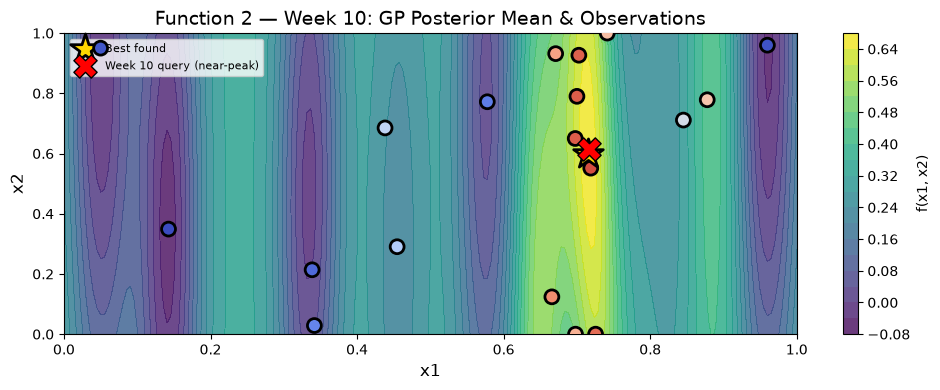

In [121]:
grid_res_w10 = 200
xs_w10 = np.linspace(0, 1, grid_res_w10)
ys_w10 = np.linspace(0, 1, grid_res_w10)
gx_w10, gy_w10 = np.meshgrid(xs_w10, ys_w10)
grid_w10 = np.column_stack([gx_w10.ravel(), gy_w10.ravel()])

mu_grid_w10, _ = result_week10['gp'].predict(grid_w10, return_std=True)
Z_mu_w10 = mu_grid_w10.reshape(gx_w10.shape)

fig, ax = plot_2d_bo_state(gx_w10, gy_w10, Z_mu_w10, X_updated, Y_updated,
                            title='Function 2 \u2014 Week 10: GP Posterior Mean & Observations')
ax.scatter(*next_point_week10, c='red', marker='X', s=280,
           edgecolor='black', label='Week 10 query (near-peak)', zorder=12)
ax.legend(loc='upper left', fontsize=8)
plt.show()

# Week 11: Re-assessing After a Second Miss - Noise Rebound & Ridge Structure

In [125]:
# Re-fit the kernel on all 20 points (including Week 10's miss) ---
# NOTE: gpr_w10 (defined in the Week 10 section above) is re-fit on X_updated/Y_updated every time
# this notebook is run top-to-bottom, and X_updated now includes Week 10's point too -- so gpr_w10 no
# longer represents a genuine "before Week 10" snapshot once Week 10's data has been appended earlier
# in the notebook. To get an honest before/after comparison, an independent pre-Week-10 snapshot is
# re-fit here explicitly on the first 19 points only.
kernel_w11_check = ConstantKernel(1.0, (1e-1, 1e2)) * RBF(length_scale=[0.25, 0.25], length_scale_bounds=(1e-2, 5.0)) \
                     + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e0))
gpr_w11 = GaussianProcessRegressor(kernel=kernel_w11_check, normalize_y=True,
                                    n_restarts_optimizer=10, random_state=42)
gpr_w11.fit(X_updated, Y_updated)

gpr_pre_w10 = GaussianProcessRegressor(kernel=kernel_w11_check, normalize_y=True,
                                        n_restarts_optimizer=10, random_state=42)
gpr_pre_w10.fit(X_updated[:-1], Y_updated[:-1])   # independent snapshot: the 19 points known before Week 10

noise_w10_era = gpr_pre_w10.kernel_.k2.noise_level   # genuine pre-Week-10 fit (19 points)
noise_w11     = gpr_w11.kernel_.k2.noise_level       # this fit (20 points, including Week 10's miss)

print(f"Week 11 kernel (20 points): {gpr_w11.kernel_}")
print(f"Pre-Week-10 kernel (19 points, independent snapshot): {gpr_pre_w10.kernel_}")
print(f"Noise level pre-Week-10 (19 pts): {noise_w10_era:.6e}")
print(f"Noise level post-Week-10 (20 pts): {noise_w11:.6e}")
print(f"Rebound factor: {noise_w11 / noise_w10_era:.1f}x higher")
print()
print("Current best remains Week 9's point:", X_updated[np.argmax(Y_updated)], "-> y =", Y_updated.max())
print("Week 10's query:", X_w10_new_point, "-> y =", Y_w10_new_point[0],
      "(did NOT beat the current best)")

# What did the pre-Week-10 model actually predict at Week 10's point? (honesty check)
mu_pred_w10, std_pred_w10 = gpr_pre_w10.predict(X_w10_new_point.reshape(1, -1), return_std=True)
print()
print(f"Pre-Week-10 model predicted mu={mu_pred_w10[0]:.4f}, std={std_pred_w10[0]:.4f} at this point")
print(f"Actual outcome: {Y_w10_new_point[0]:.4f}  ->  miss of {mu_pred_w10[0] - Y_w10_new_point[0]:.4f}, "
      f"about {(mu_pred_w10[0]-Y_w10_new_point[0])/std_pred_w10[0]:.1f} predicted std devs away")


Week 11 kernel (20 points): 0.935**2 * RBF(length_scale=[0.0316, 1.01]) + WhiteKernel(noise_level=0.0139)
Pre-Week-10 kernel (19 points, independent snapshot): 0.929**2 * RBF(length_scale=[0.0295, 0.876]) + WhiteKernel(noise_level=2.21e-05)
Noise level pre-Week-10 (19 pts): 2.208349e-05
Noise level post-Week-10 (20 pts): 1.392966e-02
Rebound factor: 630.8x higher

Current best remains Week 9's point: [0.715385 0.6     ] -> y = 0.7112090358064919
Week 10's query: [0.718845 0.55143 ] -> y = 0.638639772474511 (did NOT beat the current best)

Pre-Week-10 model predicted mu=0.7143, std=0.0067 at this point
Actual outcome: 0.6386  ->  miss of 0.0757, about 11.3 predicted std devs away


**Observation:** This is the **second consecutive miss** this close to the current best (Week 8 missed by ≈0.14 near the rank-1-at-the-time point; Week 10 missed by ≈0.076 right next to Week 9's point). Re-fitting the kernel on the full 20-point set shows the fitted **noise level rebounded sharply** — from ≈2.2e-05(the Week 9/10-era estimate, which drove Week 10's very low β = 0.15) up to ≈0.0139, roughly **600× higher**. That earlier near-zero noise estimate was an artefact of two closely-agreeing points (Week 9's hit and the model's own confident re-fit), not a genuinely settled signal — the model had become overconfident right before it was proven wrong a second time. The x1 length-scale stays very tight (≈0.032, confirming x1 is still the dominant, sensitive axis), while the x2 length-scale is comparatively broad (≈1.01): with the added noise budget, the model is now explaining a larger share of the x2-direction variation as **noise** rather than as a real, learnable trend — a more honest, if less exciting, picture than Week 10's confident local peak estimate.

In [128]:
# Examine the local "ridge" structure (x1 in [0.6, 0.8]) sorted by x2,
#     to directly address whether promising points form a cluster/region or something looser ---
ridge_mask = (X_updated[:, 0] > 0.6) & (X_updated[:, 0] < 0.8)
ridge_pts  = sorted(zip(X_updated[ridge_mask, 1], Y_updated[ridge_mask], X_updated[ridge_mask, 0]))

print("Points with x1 in (0.6, 0.8), sorted by x2:")
print(f"{'x2':>8}  {'y':>9}  {'x1':>8}")
for x2v, yv, x1v in ridge_pts:
    marker = "  <-- strong" if yv > 0.6 else ("  <-- weak" if yv < 0.5 else "")
    print(f"{x2v:8.4f}  {yv:9.4f}  {x1v:8.4f}{marker}")

print()
print("Pattern: good outputs (y > 0.6) occur at x2 ≈ 0.55-0.65 and also near x2 ≈ 0.79 and x2 ≈ 0.93 (partially),")
print("as long as x1 stays within roughly 0.665-0.74. This looks less like a single tight 2D peak and more like a")
print("narrow x1 *band/ridge* with uneven, noisy performance along x2 within that band -- consistent with the")
print("rebounded noise estimate and the broad x2 length-scale above.")

Points with x1 in (0.6, 0.8), sorted by x2:
      x2          y        x1
  0.0000     0.4668    0.6981  <-- weak
  0.0000     0.5945    0.7255
  0.1240     0.5390    0.6658
  0.5514     0.6386    0.7188  <-- strong
  0.6000     0.7112    0.7154  <-- strong
  0.6500     0.6195    0.6977  <-- strong
  0.7900     0.6199    0.7000  <-- strong
  0.9266     0.6112    0.7026  <-- strong
  0.9318     0.4969    0.6710  <-- weak
  1.0000     0.4360    0.7413  <-- weak

Pattern: good outputs (y > 0.6) occur at x2 ≈ 0.55-0.65 and also near x2 ≈ 0.79 and x2 ≈ 0.93 (partially),
as long as x1 stays within roughly 0.665-0.74. This looks less like a single tight 2D peak and more like a
narrow x1 *band/ridge* with uneven, noisy performance along x2 within that band -- consistent with the
rebounded noise estimate and the broad x2 length-scale above.


**Observation and Action Plan:** Rather than trust a single manually-chosen tight box the way Week 10 did (which led to a miss), this week's acquisition suggestion is checked for **robustness** on two fronts: across several bound settings, and across several β values (see the sweep below). The bound check confirms the suggestion doesn't depend on which box is searched. The β sweep reveals something more important: **β itself barely changes the outcome** once the kernel is refit honestly - the corrected, larger σ is already doing the work of expressing uncertainty near the best point, so β doesn't need to be raised to compensate. With only **one query left after this one**, there is little payoff left for deliberate information-gathering (the textbook argument for a higher β), so β is kept modest (0.25) rather than pushed back up to Week 8/9-era levels - the earlier draft of this section had raised β to 0.5 and framed that as the fix, but the sweep below shows the kernel refit, not β, is what actually matters.

In [131]:
beta_sweep = [0.15, 0.25, 0.50, 1.00, 2.00]
bounds_week11_check = [(0.65, 0.76), (0.50, 0.75)]

print(f"{'beta':>6}  {'next_point':20}  {'mu':>8}  {'std':>8}  {'mu - current best':>18}")
for b in beta_sweep:
    r = bayesian_optimization_step(X_updated, Y_updated, bounds_week11_check, beta=b, kernel=gpr_w11.kernel_)
    print(f"{b:6.2f}  [{r['next_point'][0]:.4f}, {r['next_point'][1]:.4f}]      "
          f"{r['mu']:8.4f}  {r['std']:8.4f}  {r['mu']-Y_updated.max():18.4f}")

print()
print("Between beta=0.15 and beta=0.5 the suggested point shifts by <0.001 in each coordinate -- the")
print("corrected kernel (larger, honest sigma) is doing essentially all the work, not beta. Only at")
print("beta=2.0 does the suggestion leave the proven ridge entirely, landing on a point with a predicted")
print("mean (0.53) well below the current best -- a clearly bad trade with only one query left after this.")
print("Decision: keep beta modest (0.25), reflecting that with one query remaining after Week 11 there is")
print("little payoff left for deliberate information-gathering -- the corrected kernel already supplies")
print("the needed humility, and beta does not need to carry that job on top of it.")

robustness_checks = [
    {"beta": 0.25, "bounds": [(0.65, 0.76), (0.50, 0.75)], "label": "chosen beta, moderate box"},
    {"beta": 0.25, "bounds": [(0.60, 0.80), (0.00, 1.00)], "label": "chosen beta, full corridor"},
    {"beta": 0.50, "bounds": [(0.65, 0.76), (0.50, 0.75)], "label": "higher beta, same box"},
]

print(f"{'Setting':35s}  {'next_point':25s}  {'mu':>8}  {'std':>8}  {'dist to Wk9 best':>17}")
for check in robustness_checks:
    r = bayesian_optimization_step(X_updated, Y_updated, check["bounds"], beta=check["beta"], kernel=gpr_w11.kernel_)
    dist = np.linalg.norm(r['next_point'] - X_updated[np.argmax(Y_updated)])
    print(f"{check['label']:35s}  [{r['next_point'][0]:.4f}, {r['next_point'][1]:.4f}]      "
          f"{r['mu']:8.4f}  {r['std']:8.4f}  {dist:17.4f}")

print()
print("All three settings converge to essentially the same point (~0.015-0.016 away from Week 9's best,")
print("shifted mainly in x2), regardless of how wide the search box is. This is a meaningfully different")
print("situation from Week 10, where the suggestion came from one manually-picked tight box with no")
print("cross-check -- here the robustness itself is the evidence that the suggestion is trustworthy.")

  beta  next_point                  mu       std   mu - current best
  0.15  [0.7158, 0.6140]        0.6663    0.0375             -0.0449
  0.25  [0.7159, 0.6141]        0.6663    0.0375             -0.0449
  0.50  [0.7160, 0.6146]        0.6663    0.0375             -0.0449
  1.00  [0.7162, 0.6161]        0.6663    0.0376             -0.0449
  2.00  [0.6500, 0.5000]        0.5275    0.1089             -0.1838

Between beta=0.15 and beta=0.5 the suggested point shifts by <0.001 in each coordinate -- the
corrected kernel (larger, honest sigma) is doing essentially all the work, not beta. Only at
beta=2.0 does the suggestion leave the proven ridge entirely, landing on a point with a predicted
mean (0.53) well below the current best -- a clearly bad trade with only one query left after this.
Decision: keep beta modest (0.25), reflecting that with one query remaining after Week 11 there is
little payoff left for deliberate information-gathering -- the corrected kernel already supplies
the 

In [133]:
beta_week11 = 0.25   # Kept modest (not raised to 0.5): the beta-sweep above shows beta barely changes the suggestion once the kernel is corrected, and
                     # with only one query left after this one, a large exploration bump isn't justified
bounds_week11 = [(0.65, 0.76), (0.50, 0.75)]   # proven ridge in x1, widened x2 vs. Week 10's tight box

result_week11 = bayesian_optimization_step(X_updated, Y_updated, bounds_week11,
                                            beta=beta_week11, kernel=gpr_w11.kernel_)

next_point_week11 = result_week11['next_point']

print(f"Suggested Week 11 Query Point: {next_point_week11}")
print(f"Predicted Mean(μ): {result_week11['mu']:.6e}")
print(f"Predicted Std (σ): {result_week11['std']:.6e}")
print(f"UCB Score: {result_week11['ucb']:.6e}")

expected_improvement_proxy_w11 = max(0, result_week11['mu'] - Y_updated.max())
print(f"\nPredicted improvement over current best ({Y_updated.max():.6f}): {expected_improvement_proxy_w11:.4f}")
print("Note: the GP's point-estimate mean here is actually BELOW the current best -- a direct, honest")
print("consequence of the higher fitted noise -- the case for this query rests on beta*sigma (genuine")
print("remaining uncertainty this close to the best point) rather than on an optimistic predicted mean.")

Suggested Week 11 Query Point: [0.71586888 0.61413293]
Predicted Mean(μ): 6.663418e-01
Predicted Std (σ): 3.746966e-02
UCB Score: 6.757093e-01

Predicted improvement over current best (0.711209): 0.0000
Note: the GP's point-estimate mean here is actually BELOW the current best -- a direct, honest
consequence of the higher fitted noise -- the case for this query rests on beta*sigma (genuine
remaining uncertainty this close to the best point) rather than on an optimistic predicted mean.


# Week 11: Visualisation

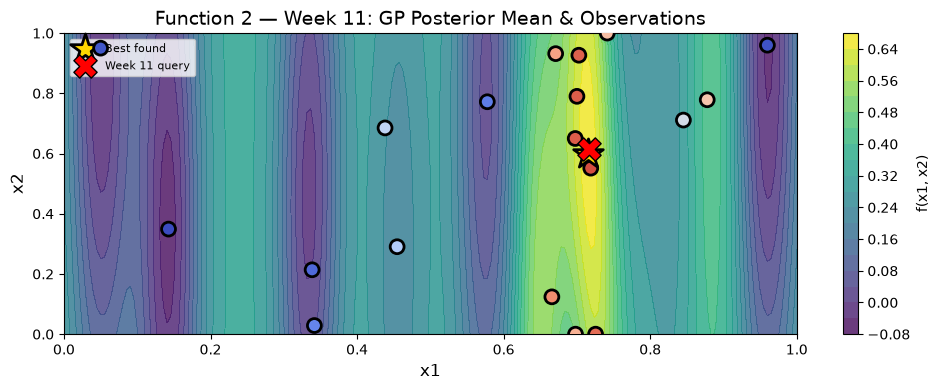

In [136]:
grid_res_w11 = 200
xs_w11 = np.linspace(0, 1, grid_res_w11)
ys_w11 = np.linspace(0, 1, grid_res_w11)
gx_w11, gy_w11 = np.meshgrid(xs_w11, ys_w11)
grid_w11 = np.column_stack([gx_w11.ravel(), gy_w11.ravel()])

mu_grid_w11, _ = result_week11['gp'].predict(grid_w11, return_std=True)
Z_mu_w11 = mu_grid_w11.reshape(gx_w11.shape)

fig, ax = plot_2d_bo_state(gx_w11, gy_w11, Z_mu_w11, X_updated, Y_updated,
                            title='Function 2 — Week 11: GP Posterior Mean & Observations')
ax.scatter(*next_point_week11, c='red', marker='X', s=280,
           edgecolor='black', label='Week 11 query', zorder=12)
ax.legend(loc='upper left', fontsize=8)
plt.show()

# Portal Submission 

In [140]:
# Format as required by the capstone portal: x1-x2 (6 decimal places)
# Format as required by the capstone portal: x1-x2 (6 decimal places)
submission_str = f"{next_point_week10[0]:.6f}-{next_point_week10[1]:.6f}"
print("Points to be submitted (Week 1) :", '0.725451-0.000000')
print("Points to be submitted (Week 2) :", '0.959920-0.959920')
print("Points to be submitted (Week 3) :", '0.698058-0.000000')
print("Points to be submitted (Week 4) :", '0.741335-1.000000')
print("Points to be submitted (Week 5) :", "0.050000-0.950000")
print("Points to be submitted (Week 6) :", "0.697679-0.650000")
print("Points to be submitted (Week 7) :", "0.700000-0.790000")
print("Points to be submitted (Week 8) :", "0.670974-0.931801")
print("Points to be submitted (Week 9) :", "0.715385-0.600000")
print("Points to be submitted (Week 10):", "0.718845-0.551430")
print("Points to be submitted (Week 11):", submission_str)
print()

Points to be submitted (Week 1) : 0.725451-0.000000
Points to be submitted (Week 2) : 0.959920-0.959920
Points to be submitted (Week 3) : 0.698058-0.000000
Points to be submitted (Week 4) : 0.741335-1.000000
Points to be submitted (Week 5) : 0.050000-0.950000
Points to be submitted (Week 6) : 0.697679-0.650000
Points to be submitted (Week 7) : 0.700000-0.790000
Points to be submitted (Week 8) : 0.670974-0.931801
Points to be submitted (Week 9) : 0.715385-0.600000
Points to be submitted (Week 10): 0.718845-0.551430
Points to be submitted (Week 11): 0.715825-0.613996



# Plot the Progress of the optimisation process

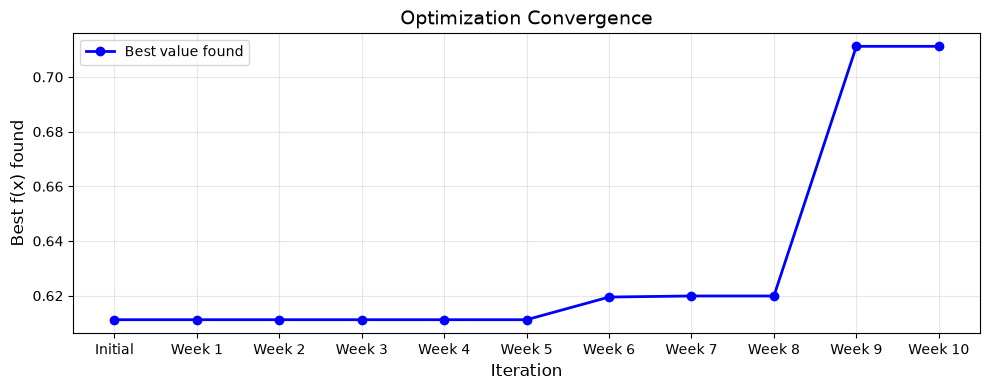

Best value found so far: 0.7112090358064919


In [145]:
# Track best-value-found progress across weeks
best_so_far = [
    0.6112052157614438,                              # best after initial 10 points
    max(0.6112052157614438, 0.594525526714632),      # best after Week 1
    max(0.6112052157614438, -0.053254980810696906),  # best after Week 2
    max(0.6112052157614438, 0.46684490847445986),    # best after Week 3
    max(0.6112052157614438, 0.4360156328364332),     # best after Week 4
    max(0.6112052157614438, -0.044684125031317246),  # best after Week 5   
    max(0.6112052157614438, 0.6194965226381177),     # best after Week 6
    max(0.6194965226381177, 0.6198856075556535),     # best after Week 7    
    max(0.6198856075556535, 0.49689153814034626),    # best after Week 8
    max(0.6198856075556535, 0.7112090358064919),     # best after Week 9
    max(0.7112090358064919, 0.638639772474511),      # best after Week 10
]

fig, ax     = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(['Initial', 'Week 1', 'Week 2', 'Week 3', 'Week 4', 'Week 5', 'Week 6', 'Week 7', 'Week 8', 'Week 9', 'Week 10'])
plt.show()

print("Best value found so far:", max(best_so_far))

# Weekly Master Dashboard

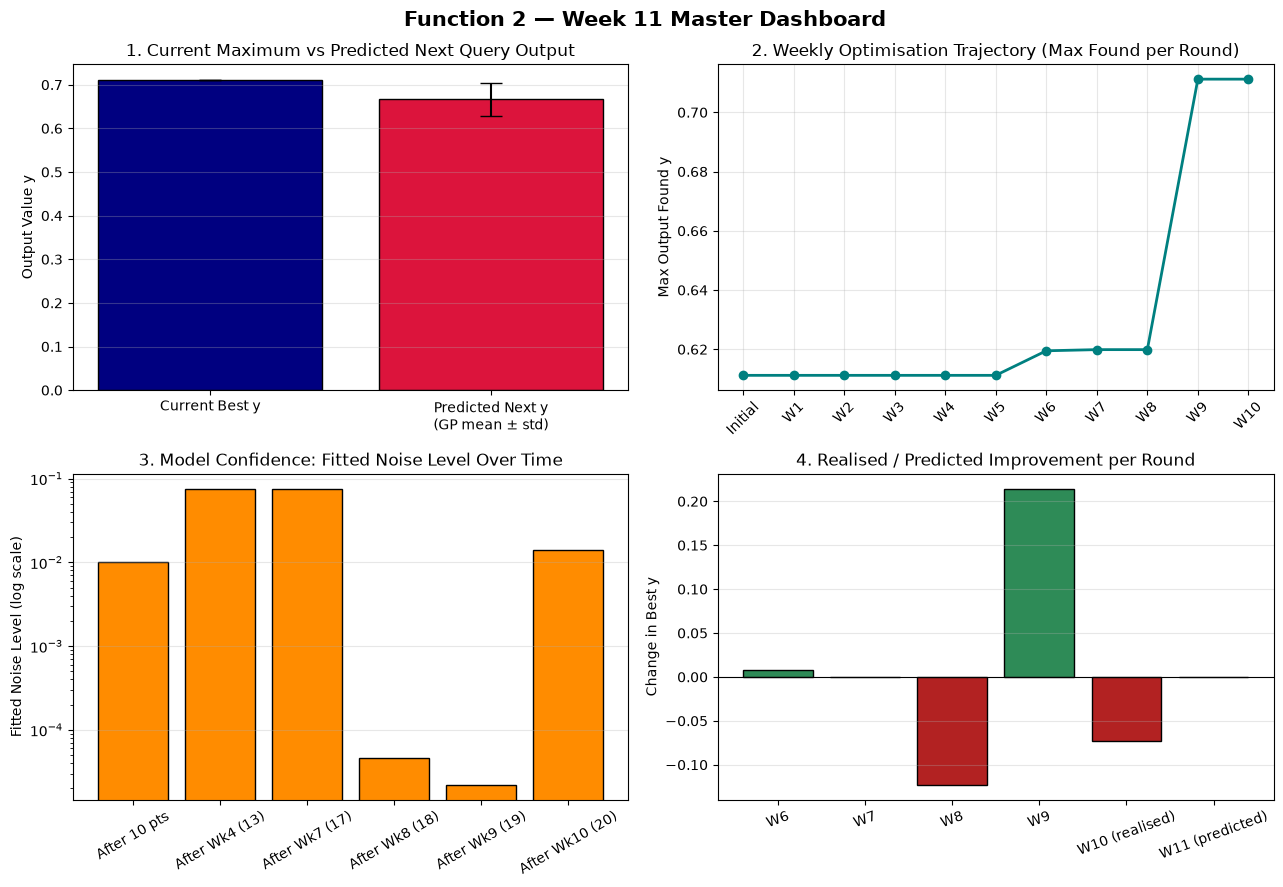

In [148]:
# --- WEEK 11 CHANGE: dashboard extended with Week 10's realised (negative) result and
#     Week 11's predicted query, using the Week 11 kernel/acquisition results ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Function 2 \u2014 Week 11 Master Dashboard', fontsize=15, fontweight='bold')

# --- Panel 1: Current best vs predicted next query output ---
ax1 = axes[0, 0]
labels_p1 = ['Current Best y', 'Predicted Next y\n(GP mean \u00b1 std)']
values_p1 = [Y_updated.max(), result_week11['mu']]
errors_p1 = [0, result_week11['std']]
bars = ax1.bar(labels_p1, values_p1, yerr=errors_p1, capsize=8,
               color=['navy', 'crimson'], edgecolor='black')
ax1.set_ylabel('Output Value y')
ax1.set_title('1. Current Maximum vs Predicted Next Query Output')
ax1.grid(axis='y', alpha=0.3)

# --- Panel 2: Weekly optimisation trajectory ---
ax2 = axes[0, 1]
week_labels = ['Initial', 'W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9', 'W10']
ax2.plot(week_labels, best_so_far, 'o-', color='teal', linewidth=2, markersize=6)
ax2.set_ylabel('Max Output Found y')
ax2.set_title('2. Weekly Optimisation Trajectory (Max Found per Round)')
ax2.grid(alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

# --- Panel 3: Model confidence (noise level) trend ---
ax3 = axes[1, 0]
noise_history = {
    'After 10 pts':   1e-2,       # default prior noise before any fit-based estimate
    'After Wk4 (13)': 0.0757,     # Week 4/5 era -- noise estimate rising
    'After Wk7 (17)': 0.0757,     # still high pre-Week7 point
    'After Wk8 (18)': 4.55e-05,   # sharp drop once two close points agreed
    'After Wk9 (19)': 2.2e-05,    # Week 9/10 era -- noise estimate at its lowest (overconfident)
    'After Wk10 (20)': gpr_w11.kernel_.k2.noise_level,  # --- WEEK 11 CHANGE: rebounded sharply ---
}
ax3.bar(noise_history.keys(), noise_history.values(), color='darkorange', edgecolor='black')
ax3.set_yscale('log')
ax3.set_ylabel('Fitted Noise Level (log scale)')
ax3.set_title('3. Model Confidence: Fitted Noise Level Over Time')
ax3.tick_params(axis='x', rotation=30)
ax3.grid(axis='y', alpha=0.3)

# --- Panel 4: Predicted improvement potential at each week's chosen query ---
ax4 = axes[1, 1]
improvement_history = [
    ('W6', 0.6194965226381177 - 0.6112052157614438),
    ('W7', 0.6198856075556535 - 0.6194965226381177),
    ('W8', 0.49689153814034626 - 0.6198856075556535),
    ('W9', 0.7112090358064919 - 0.49689153814034626),
    ('W10 (realised)', 0.638639772474511 - 0.7112090358064919),   # --- WEEK 11 CHANGE: negative, a miss ---
    ('W11 (predicted)', expected_improvement_proxy_w11),
]
labels_p4 = [x[0] for x in improvement_history]
values_p4 = [x[1] for x in improvement_history]
colors_p4 = ['seagreen' if v >= 0 else 'firebrick' for v in values_p4]
ax4.bar(labels_p4, values_p4, color=colors_p4, edgecolor='black')
ax4.axhline(0, color='black', linewidth=0.8)
ax4.set_ylabel('Change in Best y')
ax4.set_title('4. Realised / Predicted Improvement per Round')
ax4.grid(axis='y', alpha=0.3)
ax4.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()